# Exploratory Data Analysis: USD/KZT, inflation, base rate and Brent

**Goal of the project:** analyse the dynamics of the USD/KZT exchange rate, inflation and the
NBK base rate, and forecast **USD/KZT** (target) using the other series as features.

**What this notebook covers**

| # | Section | Course requirement |
|---|---------|--------------------|
| 1 | Setup and loading | |
| 2 | Data overview and descriptive statistics | EDA: descriptive statistics |
| 3 | Missing values and time-index continuity | EDA: missing values, frequency, weekends |
| 4 | Outliers | EDA: outliers |
| 5 | Merging sources with different frequencies → **one monthly dataframe** | daily + monthly + annual data |
| 6 | Visual overview (interactive Plotly) | 4–5 charts, at least one Plotly |
| 7 | Structural breaks: 2009, 2014–2015 devaluations, 2022 shock | structural breaks |
| 8 | Time series analysis: resample, rolling means, STL, ADF/KPSS, ACF/PACF | time series block |
| 9 | Seasonality | input for seasonal naive |
| 10 | Correlations with external factors (Brent, base rate, inflation) | correlation with oil |
| 11 | Key findings and modelling plan | input for ARIMA vs naive |

Data sources (`data/raw/`): NBK daily official USD/KZT rate, NBK base rate decisions, IMF monthly CPI
(2020 = 100), FRED daily Brent price, World Bank annual indicators.

## 1. Setup and loading

In [1]:
import io
import warnings
from contextlib import redirect_stdout
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, grangercausalitytests, kpss

warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

plt.rcParams.update({
    "figure.figsize": (13, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pio.renderers.default = "plotly_mimetype+notebook_connected"

In [3]:
# Works whether the notebook is started from the project root or from EDA/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

# Month-start labels: valid in pandas 2.x and 3.x and match the CPI dates (YYYY-MM-01)
MONTH = "MS"

Known shock dates and crisis windows used throughout the notebook (shading on charts,
regime statistics, dummy features).

In [4]:
EVENTS = {
    "2009-02-04": "Devaluation 2009",
    "2014-02-11": "Devaluation 2014",
    "2015-08-20": "Free float 2015",
    "2022-02-24": "2022 shock",
}

CRISIS_WINDOWS = [
    ("2008-09-01", "2009-06-30", "GFC + 2009 devaluation"),
    ("2014-01-01", "2016-03-31", "2014-2015 devaluations"),
    ("2020-03-01", "2020-05-31", "COVID"),
    ("2022-02-01", "2022-12-31", "2022 shock"),
]


def shade_events(ax, labels=False):
    """Shade crisis windows and mark shock dates on a matplotlib axis."""
    for start, end, name in CRISIS_WINDOWS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="tab:red", alpha=0.08,
                   label=name if labels else None)
    for day in EVENTS:
        ax.axvline(pd.Timestamp(day), color="tab:red", ls="--", lw=0.8)

In [5]:
fx_raw = pd.read_csv(RAW / "usd_kzt_daily.csv", parse_dates=["date"]).rename(columns={"rate": "usd_kzt"})
brent_raw = pd.read_csv(RAW / "brent_daily.csv", parse_dates=["date"])
cpi_raw = pd.read_csv(RAW / "cpi_monthly.csv", parse_dates=["date"])
rate_raw = pd.read_csv(RAW / "base_rate.csv", parse_dates=["date"]).rename(columns={"rate": "base_rate"})
wb_raw = pd.read_csv(RAW / "world_bank_annual.csv")

## 2. Data overview and descriptive statistics

### 2.1 Shape, period and duplicates of each source

In [6]:
def overview(name, df, date_col, key_cols):
    return {
        "dataset": name,
        "rows": len(df),
        "columns": ", ".join(df.columns),
        "start": df[date_col].min(),
        "end": df[date_col].max(),
        "missing values": int(df.isna().sum().sum()),
        "duplicate keys": int(df.duplicated(key_cols).sum()),
    }


pd.DataFrame([
    overview("USD/KZT (daily)", fx_raw, "date", ["date"]),
    overview("Brent (daily)", brent_raw, "date", ["date"]),
    overview("CPI (monthly)", cpi_raw, "date", ["date"]),
    overview("Base rate (decisions)", rate_raw, "date", ["date"]),
    overview("World Bank (annual)", wb_raw, "year", ["indicator", "year"]),
]).set_index("dataset")

,rows,columns,start,end,missing values,duplicate keys
dataset,,,,,,
USD/KZT (daily),9758,"date, usd_kzt",2000-01-01 00:00:00,2026-11-12 00:00:00,0,0
Brent (daily),6501,"date, brent_usd",2000-01-04 00:00:00,2026-11-03 00:00:00,0,0
CPI (monthly),261,"date, cpi_index",2005-01-01 00:00:00,2026-09-01 00:00:00,0,0
Base rate (decisions),92,"date, base_rate",2015-09-02 00:00:00,2026-10-27 00:00:00,0,0
World Bank (annual),203,"indicator, code, year, value",1990,2025,0,0


In [7]:
for name, df in [("USD/KZT", fx_raw), ("Brent", brent_raw), ("CPI", cpi_raw), ("Base rate", rate_raw)]:
    print(f"{name:10s}", dict(df.dtypes.astype(str)))

USD/KZT    {'date': 'datetime64[ns]', 'usd_kzt': 'float64'}
Brent      {'date': 'datetime64[ns]', 'brent_usd': 'float64'}
CPI        {'date': 'datetime64[ns]', 'cpi_index': 'float64'}
Base rate  {'date': 'datetime64[ns]', 'base_rate': 'float64'}


The World Bank file is in long format (one row per indicator-year); pivot it to one column per indicator.

In [8]:
wb = wb_raw.pivot(index="year", columns="indicator", values="value")
wb["gdp_current_usd"] = wb["gdp_current_usd"] / 1e9  # billions of USD
wb = wb.rename(columns={"gdp_current_usd": "gdp_usd_bn"})
wb.tail(8)

indicator,exports_pct_gdp,gdp_usd_bn,gdp_growth_pct,inflation_cpi_pct,unemployment_pct,usd_kzt_annual_avg
year,,,,,,
2018,37.625,179.340,4.100,6.164,4.850,344.706
2019,36.439,181.667,4.500,5.334,4.800,382.747
2020,30.529,171.082,-2.500,6.804,4.890,412.953
2021,33.645,197.112,4.300,7.960,5.568,425.908
2022,41.569,225.496,3.200,14.995,4.860,460.165
2023,34.651,261.840,5.100,14.522,4.835,456.165
2024,31.587,291.480,5.000,8.676,4.833,468.962
2025,NaN,306.239,6.500,11.379,4.771,521.035


Convert each source into a date-indexed series, which is the form used for the rest of the notebook.

In [9]:
fx = fx_raw.set_index("date")["usd_kzt"].sort_index()
brent = brent_raw.set_index("date")["brent_usd"].sort_index()
cpi = cpi_raw.set_index("date")["cpi_index"].sort_index()
base_rate = rate_raw.set_index("date")["base_rate"].sort_index()

### 2.2 Descriptive statistics

In [10]:
def describe(s):
    d = s.describe()
    d["skew"] = s.skew()
    d["kurtosis"] = s.kurt()
    d["cv"] = s.std() / s.mean()  # coefficient of variation
    return d


pd.concat({
    "USD/KZT (daily)": describe(fx),
    "Brent USD (daily)": describe(brent),
    "CPI index (monthly)": describe(cpi),
    "Base rate % (decisions)": describe(base_rate),
}, axis=1).T

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,cv
USD/KZT (daily),"9,758.000",257.456,140.164,117.250,145.620,154.090,388.692,549.150,0.577,-1.346,0.544
Brent USD (daily),"6,501.000",69.191,28.023,9.120,47.880,68.300,87.630,143.950,0.176,-0.798,0.405
CPI index (monthly),261.000,81.350,42.608,28.531,47.878,71.274,102.700,186.800,0.845,-0.278,0.524
Base rate % (decisions),92.000,12.796,3.232,9.000,9.250,12.750,16.000,18.000,0.128,-1.610,0.253


In [11]:
wb.describe().T

,count,mean,std,min,25%,50%,75%,max
indicator,,,,,,,,
exports_pct_gdp,33.000,41.981,9.745,28.517,34.917,39.342,46.991,74.005
gdp_usd_bn,36.000,115.674,92.424,16.871,24.330,110.079,186.448,306.239
gdp_growth_pct,35.000,3.109,6.320,-12.600,1.150,4.200,7.350,13.500
inflation_cpi_pct,32.000,73.625,330.512,5.196,6.838,8.128,13.476,"1,877.372"
unemployment_pct,35.000,6.887,3.404,0.900,4.875,5.568,8.590,13.460
usd_kzt_annual_avg,32.000,217.221,143.494,35.538,125.206,148.305,342.796,521.035


> **Interpretation.** USD/KZT moved from 117 to 549 KZT per USD. The **median (154) is far below the mean (257)** and kurtosis is negative (−1.35): the distribution has two clusters, roughly 120–190 before 2015 and 310–550 after the free float. The level is not one stable process, which already hints at a structural break. CPI grew ~6.5× since 2005 (28.5 → 186.8). The base rate ranged from 9% to 18%. Brent ranged from 9 to 144 USD/bbl. In the World Bank data the huge std of inflation (max 1,877%) comes from the hyperinflation of the early 1990s, which is outside our 2005+ window.

### 2.3 USD/KZT by year: level, range and annual change

In [12]:
fx_yearly = fx.groupby(fx.index.year).agg(["mean", "min", "max", "std"])
fx_yearly["range_%"] = (fx_yearly["max"] / fx_yearly["min"] - 1) * 100
fx_yearly["change_of_mean_%"] = (fx_yearly["mean"] / fx_yearly["mean"].shift(1) - 1) * 100
fx_yearly.index.name = "year"
fx_yearly

,mean,min,max,std,range_%,change_of_mean_%
year,,,,,,
2000,142.136,138.200,144.500,1.438,4.559,NaN
2001,146.734,145.000,150.200,1.369,3.586,3.235
2002,153.270,150.600,155.600,1.204,3.320,4.454
2003,149.541,143.660,155.750,3.197,8.416,-2.433
2004,136.038,130.000,143.330,3.305,10.254,-9.029
2005,132.877,129.830,136.120,2.039,4.845,-2.324
2006,126.066,117.250,133.850,4.408,14.158,-5.126
2007,122.551,118.790,127.000,1.980,6.911,-2.788
2008,120.294,119.480,120.870,0.349,1.163,-1.842


> **Interpretation.** Calm years (2008, 2010–2013) have an intra-year range of only 1–3%: the rate was managed. The jumps in the annual mean are 2009 (+22.6%), 2014 (+17.7%), 2015 (+24.1%) and 2016 (+53.8%, the full-year effect of the August 2015 float). Since the float even 'normal' years have ranges of 4–20%. 2022 is +8.2% on average but with a 23.5% range inside the year. In 2026 so far the tenge has strengthened (−9.0% vs the 2025 average).

**Cross-check with the World Bank.** The World Bank publishes the official annual average
rate (`usd_kzt_annual_avg`). If our daily NBK series is correct, its annual mean should be
almost identical.

In [13]:
check = pd.DataFrame({
    "NBK daily → annual mean": fx_yearly["mean"],
    "World Bank annual avg": wb["usd_kzt_annual_avg"],
}).dropna()
check["diff_%"] = (check.iloc[:, 0] / check.iloc[:, 1] - 1) * 100
print("Max absolute difference: {:.2f}%".format(check["diff_%"].abs().max()))
check.tail(10)

Max absolute difference: 0.24%


,NBK daily → annual mean,World Bank annual avg,diff_%
year,,,
2016,341.749,342.160,-0.120
2017,326.079,326.001,0.024
2018,344.900,344.706,0.056
2019,382.870,382.747,0.032
2020,413.359,412.953,0.098
2021,426.028,425.908,0.028
2022,460.829,460.165,0.144
2023,456.747,456.165,0.128
2024,469.113,468.962,0.032


> **Interpretation.** The annual means of the daily NBK series match the World Bank official averages to within **0.24%**, which confirms that the daily FX file is correct and complete enough for aggregation.

## 3. Missing values and time-index continuity

Each source has its own frequency, so continuity is checked against the frequency the
source *should* have: calendar days for USD/KZT, business days for Brent, months for CPI.

In [14]:
def find_gaps(index, freq):
    """Return a table of consecutive missing periods compared with a regular range."""
    full = pd.date_range(index.min(), index.max(), freq=freq)
    is_missing = ~full.isin(index)
    pos = np.flatnonzero(is_missing)
    if len(pos) == 0:
        return pd.DataFrame(columns=["start", "end", "missing_periods"])
    block = np.cumsum(np.diff(pos, prepend=-2) != 1)
    gaps = pd.Series(full[is_missing]).groupby(block).agg(start="min", end="max", missing_periods="size")
    return gaps.sort_values("missing_periods", ascending=False).reset_index(drop=True)


def coverage(name, index, freq):
    full = pd.date_range(index.min(), index.max(), freq=freq)
    missing = len(full.difference(index))
    print(f"{name}: expected {len(full):,} periods ({freq}), present {len(index):,}, "
          f"missing {missing:,} ({missing / len(full):.2%})")

### 3.1 USD/KZT: calendar coverage and gaps

In [15]:
coverage("USD/KZT", fx.index, "D")
fx_gaps = find_gaps(fx.index, "D")
fx_gaps.head(10)

USD/KZT: expected 9,813 periods (D), present 9,758, missing 55 (0.56%)


,start,end,missing_periods
0,2023-07-28,2023-08-21,25
1,2003-03-24,2003-04-01,9
2,2023-08-23,2023-08-28,6
3,2003-08-02,2003-08-03,2
4,2010-10-16,2010-10-17,2
5,2001-03-18,2001-03-18,1
6,2002-08-30,2002-08-30,1
7,2002-10-03,2002-10-03,1
8,2003-07-31,2003-07-31,1
9,2003-08-22,2003-08-22,1


### 3.2 USD/KZT: what happens on weekends?

The task notes that the market is closed on weekends. The file still has a row for every
weekday name, so check whether weekend values are real quotes or copies of the previous day.

In [16]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
unchanged = fx.diff().eq(0)

weekday_stats = pd.DataFrame({
    "rows": fx.groupby(fx.index.day_name()).size(),
    "share_unchanged_vs_previous_day": unchanged.groupby(fx.index.day_name()).mean(),
}).reindex(day_order)
weekday_stats

,rows,share_unchanged_vs_previous_day
date,,
Monday,1394,0.912
Tuesday,1396,0.269
Wednesday,1394,0.216
Thursday,1395,0.199
Friday,1392,0.210
Saturday,1394,0.225
Sunday,1393,0.978


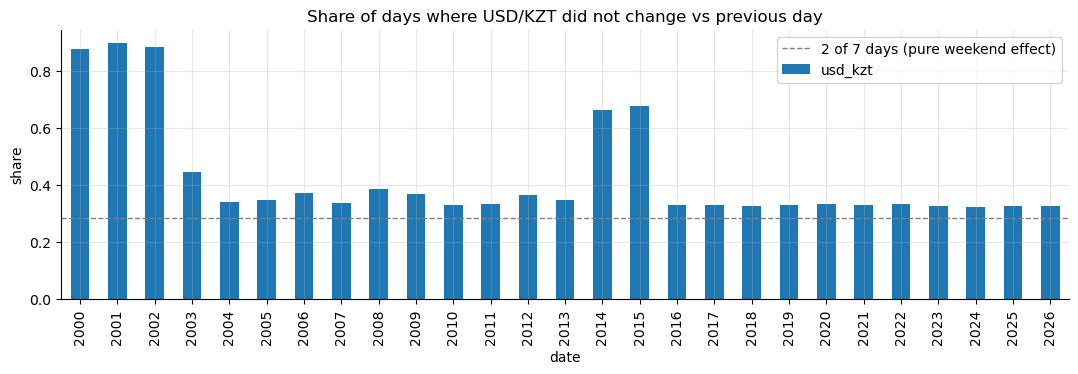

In [17]:
ax = unchanged.groupby(fx.index.year).mean().plot(kind="bar", color="tab:blue", figsize=(13, 3.5))
ax.set_title("Share of days where USD/KZT did not change vs previous day")
ax.set_ylabel("share")
ax.axhline(2 / 7, color="grey", ls="--", lw=1, label="2 of 7 days (pure weekend effect)")
ax.legend()
plt.show()

> **Interpretation.** The file has a row for **every calendar day**, but **Sunday (98%) and Monday (91%) are almost always copies of the previous day**, while Tuesday–Saturday change on ~75–80% of days. The NBK official rate for day *D* is fixed from trading on the previous business day, so Saturday carries Friday's market and Sunday/Monday repeat it. Only ~5 of 7 daily rows contain new information. This creates artificial zero returns (relevant for outliers and volatility), which is another reason to model at monthly frequency. The bar chart also shows periods when the rate was hardly moving at all: 2000–2002 (~90% unchanged days) and the 2014–2015 peg (~67%). Real gaps are small (55 days, 0.56%): one long gap **28 Jul – 28 Aug 2023 (31 days with one quote in between)** and 9 days in March 2003. They are filled by time interpolation before monthly aggregation, and `usd_kzt_obs` marks affected months (August 2023 has only 4 real quotes).

### 3.3 Brent: business-day coverage

In [18]:
print("Weekday distribution:", dict(brent.index.day_name().value_counts()))
coverage("Brent", brent.index, "B")
brent_gaps = find_gaps(brent.index, "B")
brent_gaps.head(8)

Weekday distribution: {'Wednesday': 1333, 'Thursday': 1323, 'Tuesday': 1317, 'Friday': 1292, 'Monday': 1236}
Brent: expected 7,001 periods (B), present 6,501, missing 500 (7.14%)


,start,end,missing_periods
0,2000-08-09,2000-08-17,7
1,2005-03-09,2005-03-16,6
2,2002-02-11,2002-02-18,6
3,2006-03-14,2006-03-21,6
4,2001-03-09,2001-03-15,5
5,2002-11-08,2002-11-14,5
6,2001-10-03,2001-10-09,5
7,2005-04-29,2005-05-04,4


In [19]:
# Missing business days per year (mostly exchange holidays: Christmas, New Year, Easter...)
pd.Series(1, index=pd.date_range(brent.index.min(), brent.index.max(), freq="B").difference(brent.index)) \
    .groupby(lambda d: d.year).size().to_frame("missing business days").T

,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
missing business days,57,67,67,45,32,36,31,14,9,9,9,12,12,9,8,6,6,4,9,4,7,8,8,9,8,8,6


> **Interpretation.** Brent is a business-day series (no weekends). 7.1% of business days are missing, but this is concentrated in 2000–2006 (31–67 missing days per year, sparse early data). Since 2007 only 4–14 days per year are missing, mostly exchange holidays. Monthly means are not affected.

### 3.4 CPI: monthly continuity and precision

In [20]:
coverage("CPI", cpi.index, MONTH)
decimals = cpi.astype(str).str.split(".").str[1].str.len()
decimals.groupby(cpi.index.year).max().to_frame("max decimals in value").T

CPI: expected 261 periods (MS), present 261, missing 0 (0.00%)


date,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
max decimals in value,14,14,14,14,14,14,14,14,14,14,14,14,14,14,14,14,12,1,1,1,1,1


> **Interpretation.** CPI is complete: 261 consecutive months, no gaps. Values up to 2021 have 14 decimals, values from 2022 have 1 decimal. The older part was **rebased** to 2020 = 100 (computed), while the recent part is the officially published index. Month-on-month inflation is still consistent. CPI ends in **September 2026**, one month earlier than FX (publication lag), so the model has to use lagged inflation.

### 3.5 Base rate: irregular decision dates

In [21]:
days_between = base_rate.index.to_series().diff().dt.days
print("First decision in file:", base_rate.index.min().date())
print("Days between decisions:", days_between.describe()[["mean", "min", "max"]].round(1).to_dict())
print("Decisions that changed the rate:", int(base_rate.diff().ne(0).sum() - 1), "of", len(base_rate) - 1)

base_rate.groupby(base_rate.index.year).agg(["count", "min", "max", "last"]).T

First decision in file: 2015-09-02
Days between decisions: {'mean': 44.8, 'min': 7.0, 'max': 123.0}
Decisions that changed the rate: 42 of 91


date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
count,2.000,8.000,8.000,8.000,8.000,10.000,8.000,9.000,8.000,8.000,8.000,7.000
min,12.000,12.000,10.250,9.000,9.000,9.000,9.000,10.250,15.750,14.250,15.250,15.750
max,16.000,17.000,12.000,9.750,9.250,12.000,9.750,16.750,16.750,15.250,18.000,18.000
last,16.000,12.000,10.250,9.250,9.250,9.000,9.750,16.750,15.750,15.250,18.000,15.750


> **Interpretation.** The base rate exists only **since September 2015**: it was introduced together with the free float. There are 92 decisions, on average every ~45 days (7 to 123 days apart), and only 42 of 91 changed the rate. It is a step function: the value holds until the next decision. Three tightening cycles stand out: 17% in 2016 (after the float), 16.75% in 2022–2023 (after the shock) and 18% in 2025–2026.

### 3.6 World Bank: missing years per indicator

In [22]:
wb_since_2000 = wb.loc[2000:]
pd.DataFrame({
    "first year": wb.apply(lambda s: s.first_valid_index()),
    "last year": wb.apply(lambda s: s.last_valid_index()),
    "missing since 2000": wb_since_2000.isna().sum(),
})

,first year,last year,missing since 2000
indicator,,,
exports_pct_gdp,1992,2024,1
gdp_usd_bn,1990,2025,0
gdp_growth_pct,1991,2025,0
inflation_cpi_pct,1994,2025,0
unemployment_pct,1991,2025,0
usd_kzt_annual_avg,1994,2025,0


> **Interpretation.** Annual indicators are complete since 2000, except `exports_pct_gdp` for 2025 (not yet published). They contribute only one new value per year, so they can describe the macro background but cannot explain month-to-month moves.

## 4. Outliers

For a price series, the *level* is not a useful place to look for outliers (it trends). We look at
**daily log returns** instead and use two rules:

* **IQR rule** with a wide fence (Q1 − 3·IQR, Q3 + 3·IQR), because FX returns are heavy-tailed.
  For USD/KZT it is applied only to days when the rate **actually changed**: section 3.2 showed that
  Sunday/Monday rows are copies, and these artificial zero returns would shrink the IQR and flag ~24% of days.
* **Regime-aware rule**: |return| > 6 × the standard deviation of the previous 365 days. A 2% move is
  extreme in a peg but normal in a free float, and this rule takes that into account.
* **Spike-and-revert** check: a big move immediately reversed the next day usually means a data error.

In [23]:
fx_ret = np.log(fx).diff().dropna() * 100      # % log returns
brent_ret = np.log(brent).diff().dropna() * 100


def iqr_outliers(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s[(s < q1 - k * iqr) | (s > q3 + k * iqr)]


fx_moves = fx_ret[fx_ret != 0]  # days with a real change of the rate
fx_out = iqr_outliers(fx_moves)
brent_out = iqr_outliers(brent_ret)
print(f"USD/KZT: {len(fx_out)} IQR outliers of {len(fx_moves):,} days with a change ({len(fx_out) / len(fx_moves):.1%})")
print(f"Brent:   {len(brent_out)} IQR outliers of {len(brent_ret):,} days ({len(brent_out) / len(brent_ret):.1%})")

USD/KZT: 285 IQR outliers of 5,564 days with a change (5.1%)
Brent:   65 IQR outliers of 6,500 days (1.0%)


In [24]:
def rolling_outliers(r, k=6, window=365):
    sd = r.rolling(window, min_periods=60).std().shift(1)  # volatility of the PREVIOUS year
    return r[r.abs() > k * sd]


fx_out_regime = rolling_outliers(fx_ret)
brent_out_regime = rolling_outliers(brent_ret, window=250)
print("USD/KZT regime-aware outliers:", len(fx_out_regime), "| Brent:", len(brent_out_regime))

USD/KZT regime-aware outliers: 31 | Brent: 12


Largest USD/KZT daily moves:

In [25]:
top_moves = fx_ret.abs().nlargest(12).index
pd.DataFrame({
    "rate_before": fx.shift(1).loc[top_moves],
    "rate": fx.loc[top_moves],
    "log_return_%": fx_ret.loc[top_moves],
}).sort_index()

,rate_before,rate,log_return_%
date,,,
2009-02-05,122.320,143.980,16.303
2014-02-12,155.560,163.900,5.222
2014-02-13,163.900,184.500,11.839
2015-08-21,188.380,255.260,30.382
2015-08-25,252.470,218.610,-14.400
2015-08-26,218.610,230.110,5.127
2015-08-27,230.110,243.990,5.857
2015-09-15,252.140,273.550,8.150
2015-11-06,284.280,298.920,5.022


In [26]:
# Where are the outliers? Count by year
pd.DataFrame({
    "USD/KZT (IQR)": fx_out.groupby(fx_out.index.year).size(),
    "USD/KZT (regime-aware)": fx_out_regime.groupby(fx_out_regime.index.year).size(),
    "Brent (IQR)": brent_out.groupby(brent_out.index.year).size(),
    "Brent (regime-aware)": brent_out_regime.groupby(brent_out_regime.index.year).size(),
}).fillna(0).astype(int).T

date,2000,2001,2002,2003,2004,2005,2006,2008,2009,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
USD/KZT (IQR),1,0,0,0,0,0,5,0,2,3,30,51,7,21,2,13,0,58,21,14,24,33
USD/KZT (regime-aware),1,2,4,7,0,1,1,0,2,2,2,0,0,1,0,3,0,2,0,2,0,1
Brent (IQR),4,8,0,1,1,0,0,5,6,0,0,3,0,0,1,20,2,2,0,0,0,12
Brent (regime-aware),0,1,0,0,0,0,0,1,0,1,2,0,0,0,0,6,1,0,0,0,0,0


In [27]:
# Spike-and-revert check (possible data errors): |r_t| > 3% and the next day reverses by > 3%
nxt = fx_ret.shift(-1)
spikes = fx_ret[(fx_ret.abs() > 3) & (nxt.abs() > 3) & (np.sign(fx_ret) != np.sign(nxt))]
print("Spike-and-revert days:", len(spikes))
spikes

Spike-and-revert days: 1


date
2015-08-25   -14.400
Name: usd_kzt, dtype: float64

In [28]:
print("Non-positive prices -> USD/KZT:", int((fx <= 0).sum()), "| Brent:", int((brent <= 0).sum()))

Non-positive prices -> USD/KZT: 0 | Brent: 0


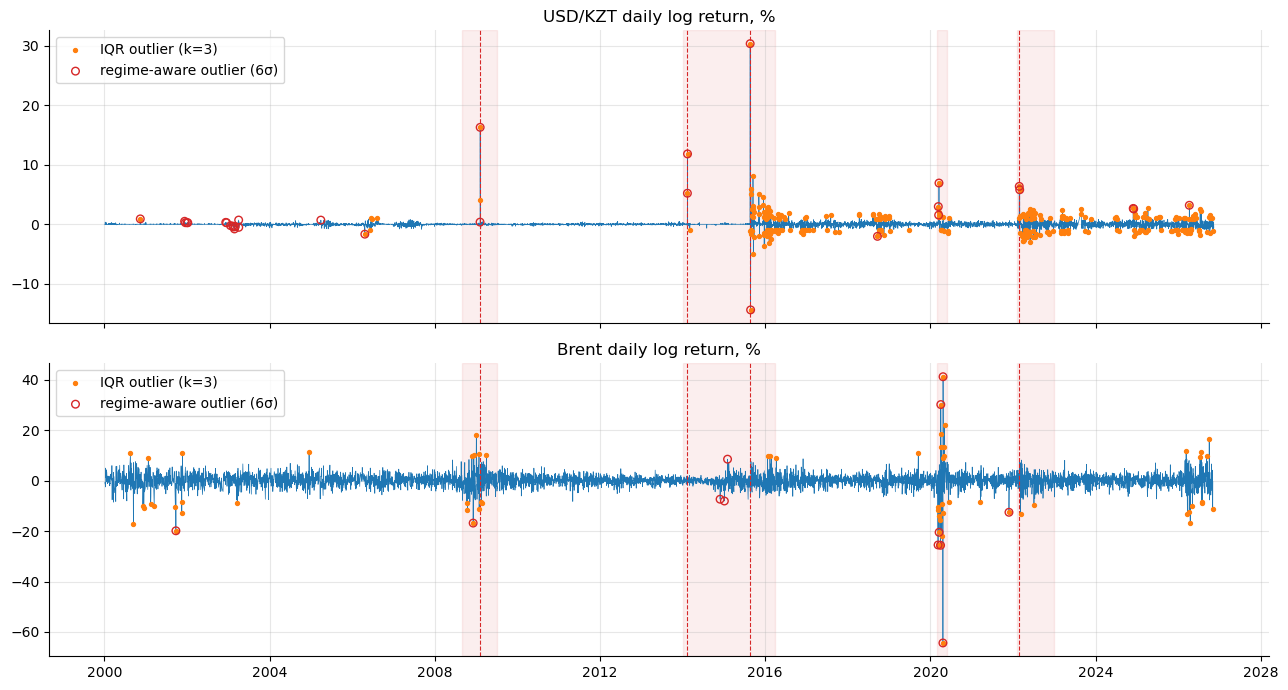

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, ret, out, out_reg, title in [
    (axes[0], fx_ret, fx_out, fx_out_regime, "USD/KZT daily log return, %"),
    (axes[1], brent_ret, brent_out, brent_out_regime, "Brent daily log return, %"),
]:
    ax.plot(ret.index, ret, lw=0.5, color="tab:blue")
    ax.scatter(out.index, out, s=8, color="tab:orange", zorder=3, label="IQR outlier (k=3)")
    ax.scatter(out_reg.index, out_reg, s=30, facecolors="none", edgecolors="tab:red", zorder=4,
               label="regime-aware outlier (6σ)")
    shade_events(ax)
    ax.set_title(title)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

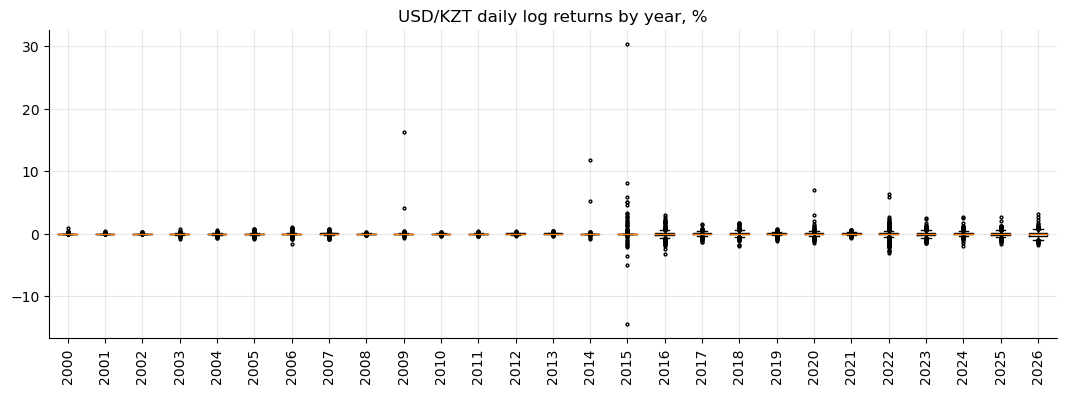

In [30]:
fig, ax = plt.subplots(figsize=(13, 4))
years = sorted(fx_ret.index.year.unique())
ax.boxplot([fx_ret[fx_ret.index.year == y] for y in years], showfliers=True, flierprops={"markersize": 2})
ax.set_xticks(range(1, len(years) + 1), years)
ax.set_title("USD/KZT daily log returns by year, %")
ax.tick_params(axis="x", rotation=90)
plt.show()

> **Interpretation.** Most of the extreme days are **real economic events, not errors**: 2009-02-05 (+16.3% log), 2014-02-12/13 (+5.2% and +11.8%), 2015-08-21 (+30.4%, free float), 2020-03-17 (+6.9%, COVID and oil collapse), 2022-02-25 and 03-01 (+6.4%, +5.8%). The only spike-and-revert day is 2015-08-25 (−14.4% after +30.4%). It is also genuine: the market overshot in the first days of the float, and the rate went back up to 244 within two days. IQR outliers (285 days, 5.1% of days with a change) cluster in 2015–2016 and 2022 and since the float generally. The regime-aware rule (31 days) flags the devaluation days, and also small moves in 2001–2003. Those moves are extreme only relative to the almost-fixed rate of that time, so 'outlier' depends on the regime. Brent outliers (65 IQR, 12 regime-aware) cluster in 2008–2009, 2020 (COVID) and 2026. **Decision:** keep all observations. Do not clip the target. Represent the shocks with the `crisis` / `shock_month` dummies, and evaluate forecast errors separately for crisis and calm periods.

## 5. Merging sources with different frequencies → one monthly dataframe

The common frequency is **monthly**: it is the frequency of CPI (the slowest high-frequency
source) and removes the weekend problem of the daily FX series.

| Source | Native frequency | How it becomes monthly |
|--------|------------------|------------------------|
| USD/KZT | daily (calendar days, with gaps) | fill gaps by time interpolation → monthly **mean** (target), month-end, min, max, realised volatility |
| Brent | business days | monthly mean, month-end, realised volatility |
| CPI | monthly | as is → month-on-month and year-on-year inflation |
| Base rate | irregular decision dates | step function (forward fill to daily) → monthly mean and month-end |
| World Bank | annual | **lagged by one year** and repeated over the 12 months |

**Why lag the annual data?** The World Bank value for year *Y* is only published in *Y+1*.
Using it for the months of year *Y* would leak future information into the model.

### 5.1 USD/KZT → monthly

In [31]:
fx_daily = fx.reindex(pd.date_range(fx.index.min(), fx.index.max(), freq="D"))
fx_filled = fx_daily.interpolate(method="time")
fx_filled_ret = np.log(fx_filled).diff()

fx_m = pd.DataFrame({
    "usd_kzt": fx_filled.resample(MONTH).mean(),
    "usd_kzt_eom": fx_filled.resample(MONTH).last(),
    "usd_kzt_min": fx_filled.resample(MONTH).min(),
    "usd_kzt_max": fx_filled.resample(MONTH).max(),
    "usd_kzt_vol": fx_filled_ret.pow(2).resample(MONTH).sum().pow(0.5) * 100,  # realised vol, %
    "usd_kzt_obs": fx_daily.resample(MONTH).count(),
})
print("Values filled by interpolation:", int(fx_daily.isna().sum()))
fx_m[fx_m["usd_kzt_obs"] < 25]  # months affected by gaps

Values filled by interpolation: 55


,usd_kzt,usd_kzt_eom,usd_kzt_min,usd_kzt_max,usd_kzt_vol,usd_kzt_obs
2003-03-01,151.664,152.064,151.200,152.600,0.586,23
2023-08-01,452.131,461.440,445.838,464.050,1.164,4
2026-11-01,450.175,444.760,444.760,453.870,1.354,12


### 5.2 Brent → monthly

In [32]:
brent_m = pd.DataFrame({
    "brent": brent.resample(MONTH).mean(),
    "brent_eom": brent.resample(MONTH).last(),
    "brent_vol": (np.log(brent).diff().pow(2).resample(MONTH).sum().pow(0.5) * 100),
})
brent_m.tail(3)

,brent,brent_eom,brent_vol
date,,,
2026-09-01,114.159,115.910,19.058
2026-10-01,123.927,120.150,22.482
2026-11-01,107.210,107.030,11.232


### 5.3 CPI → inflation rates

In [33]:
cpi_m = pd.DataFrame({
    "cpi_index": cpi,
    "inflation_mom": (cpi / cpi.shift(1) - 1) * 100,
    "inflation_yoy": (cpi / cpi.shift(12) - 1) * 100,
})
cpi_m.tail(3)

,cpi_index,inflation_mom,inflation_yoy
date,,,
2026-07-01,184.700,0.544,10.269
2026-08-01,185.800,0.596,9.876
2026-09-01,186.800,0.538,9.240


### 5.4 Base rate → step function → monthly

In [34]:
rate_daily = base_rate.reindex(
    pd.date_range(base_rate.index.min(), fx.index.max(), freq="D")
).ffill()

rate_m = pd.DataFrame({
    "base_rate": rate_daily.resample(MONTH).mean(),
    "base_rate_eom": rate_daily.resample(MONTH).last(),
})
rate_m.tail(3)

,base_rate,base_rate_eom
2026-09-01,16.350,16.250
2026-10-01,16.169,15.750
2026-11-01,15.750,15.750


### 5.5 World Bank annual → monthly (lagged one year)

In [35]:
wb_features = wb.drop(columns="usd_kzt_annual_avg")  # same thing as the target: not a feature
wb_full = wb_features.reindex(range(wb_features.index.min(), wb_features.index.max() + 2))
wb_lag = wb_full.shift(1).add_prefix("wb_").add_suffix("_lag1y")
wb_lag.tail(3)

indicator,wb_exports_pct_gdp_lag1y,wb_gdp_usd_bn_lag1y,wb_gdp_growth_pct_lag1y,wb_inflation_cpi_pct_lag1y,wb_unemployment_pct_lag1y
year,,,,,
2024,34.651,261.840,5.100,14.522,4.835
2025,31.587,291.480,5.000,8.676,4.833
2026,NaN,306.239,6.500,11.379,4.771


### 5.6 Join everything into one dataframe

In [36]:
START = pd.Timestamp("2005-01-01")  # CPI starts in 2005
last_day = fx.index.max()
END = last_day.to_period("M").to_timestamp()
if not last_day.is_month_end:      # drop the incomplete current month
    END -= pd.DateOffset(months=1)

monthly = pd.concat([fx_m, brent_m, cpi_m, rate_m], axis=1).loc[START:END]
monthly = monthly.join(
    wb_lag.reindex(monthly.index.year).set_axis(monthly.index)
)
monthly.index.name = "date"
print(f"{monthly.index.min():%Y-%m} → {monthly.index.max():%Y-%m}: {monthly.shape[0]} months, {monthly.shape[1]} columns")

2005-01 → 2026-10: 262 months, 19 columns


### 5.7 Derived features: target changes, real rate, regimes

In [37]:
monthly["usd_kzt_log_ret"] = np.log(monthly["usd_kzt"]).diff() * 100
monthly["brent_log_ret"] = np.log(monthly["brent"]).diff() * 100
monthly["real_rate"] = monthly["base_rate"] - monthly["inflation_yoy"]

idx = monthly.index
monthly["regime_float"] = (idx >= "2015-08-01").astype(int)   # free float since 20 Aug 2015
monthly["crisis"] = 0
for start, end, _ in CRISIS_WINDOWS:
    monthly.loc[start:end, "crisis"] = 1
monthly["shock_month"] = idx.isin(pd.to_datetime(list(EVENTS)).to_period("M").to_timestamp()).astype(int)
monthly.tail()

,usd_kzt,usd_kzt_eom,usd_kzt_min,usd_kzt_max,usd_kzt_vol,usd_kzt_obs,brent,brent_eom,brent_vol,cpi_index,inflation_mom,inflation_yoy,base_rate,base_rate_eom,wb_exports_pct_gdp_lag1y,wb_gdp_usd_bn_lag1y,wb_gdp_growth_pct_lag1y,wb_inflation_cpi_pct_lag1y,wb_unemployment_pct_lag1y,usd_kzt_log_ret,brent_log_ret,real_rate,regime_float,crisis,shock_month
date,,,,,,,,,,,,,,,,,,,,,,,,,
2026-06-01,487.866,485.820,484.780,493.150,2.432,30,85.399,70.460,15.330,183.700,0.879,10.397,17.233,17.000,NaN,306.239,6.500,11.379,4.771,3.874,-22.680,6.837,1,0,0
2026-07-01,471.745,474.630,464.710,480.720,4.492,31,83.759,96.950,24.631,184.700,0.544,10.269,16.960,16.750,NaN,306.239,6.500,11.379,4.771,-3.360,-1.940,6.691,1,0,0
2026-08-01,464.966,464.770,456.880,475.380,2.132,31,91.076,89.750,14.723,185.800,0.596,9.876,16.750,16.750,NaN,306.239,6.500,11.379,4.771,-1.447,8.375,6.874,1,0,0
2026-09-01,449.544,439.370,439.370,462.310,2.527,30,114.159,115.910,19.058,186.800,0.538,9.240,16.350,16.250,NaN,306.239,6.500,11.379,4.771,-3.373,22.590,7.110,1,0,0
2026-10-01,450.893,453.870,440.860,457.090,3.518,31,123.927,120.150,22.482,NaN,NaN,NaN,16.169,15.750,NaN,306.239,6.500,11.379,4.771,0.300,8.210,NaN,1,0,0


### 5.8 Missing values in the merged dataframe

In [38]:
pd.DataFrame({
    "missing": monthly.isna().sum(),
    "missing_%": monthly.isna().mean() * 100,
    "first_valid": monthly.apply(lambda s: s.first_valid_index()),
    "last_valid": monthly.apply(lambda s: s.last_valid_index()),
}).query("missing > 0")

,missing,missing_%,first_valid,last_valid
cpi_index,1,0.382,2005-01-01,2026-09-01
inflation_mom,2,0.763,2005-02-01,2026-09-01
inflation_yoy,13,4.962,2006-01-01,2026-09-01
base_rate,128,48.855,2015-09-01,2026-10-01
base_rate_eom,128,48.855,2015-09-01,2026-10-01
wb_exports_pct_gdp_lag1y,10,3.817,2005-01-01,2025-12-01
usd_kzt_log_ret,1,0.382,2005-02-01,2026-10-01
brent_log_ret,1,0.382,2005-02-01,2026-10-01
real_rate,129,49.237,2015-09-01,2026-09-01


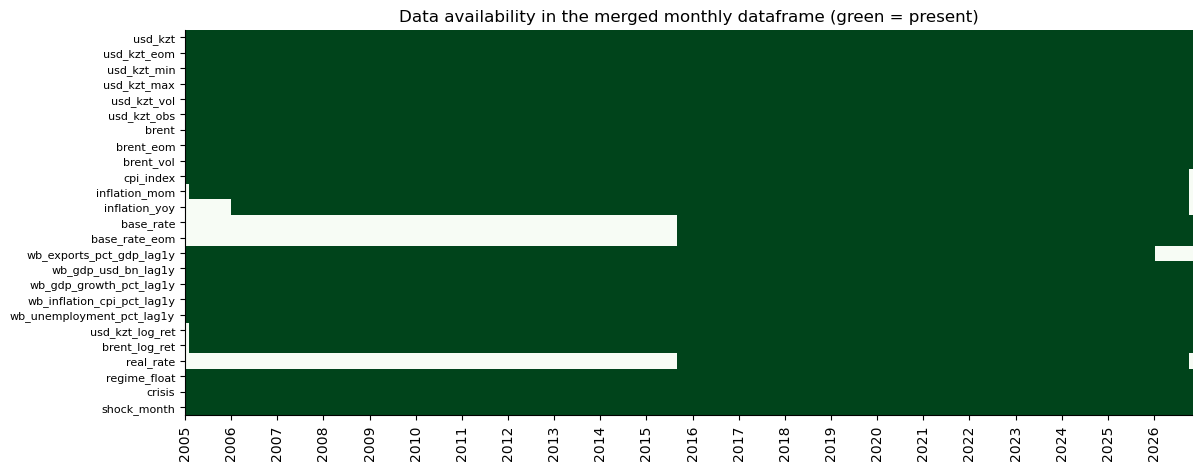

In [39]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(monthly.notna().T.values, aspect="auto", cmap="Greens", interpolation="none",
          extent=[0, len(monthly), len(monthly.columns), 0])
ax.set_yticks(np.arange(len(monthly.columns)) + 0.5, monthly.columns, fontsize=8)
years = np.flatnonzero(monthly.index.month == 1)
ax.set_xticks(years, monthly.index[years].year, rotation=90)
ax.grid(False)
ax.set_title("Data availability in the merged monthly dataframe (green = present)")
plt.show()

> **Interpretation.** The merged frame covers **2005-01 → 2026-10 (262 months)**. The incomplete current month (November 2026) is dropped. Main gap: **base rate and real rate are missing before September 2015 (49% of rows)** because the instrument did not exist. `inflation_yoy` is missing for the first 12 months by construction, CPI is missing for October 2026 (publication lag), and the lagged exports share is missing for 2026. Practical consequence: univariate models (naive, seasonal naive, ARIMA) can use the full sample, while models with the base rate as a feature should use **2015-09 onwards**, which is also the free-float regime the forecast is about.

### 5.9 Data dictionary and saving

In [40]:
data_dictionary = pd.DataFrame([
    ("usd_kzt", "NBK daily", "monthly mean", "TARGET: average USD/KZT rate in the month"),
    ("usd_kzt_eom / _min / _max", "NBK daily", "last / min / max", "month-end, min and max rate"),
    ("usd_kzt_vol", "NBK daily", "sqrt(sum r²)", "realised monthly volatility of daily log returns, %"),
    ("usd_kzt_obs", "NBK daily", "count", "number of real (not interpolated) daily quotes"),
    ("brent, brent_eom, brent_vol", "FRED daily", "mean / last / sqrt(sum r²)", "Brent price, USD/bbl"),
    ("cpi_index", "IMF monthly", "as is", "CPI, 2020 = 100"),
    ("inflation_mom / _yoy", "IMF monthly", "derived", "month-on-month and year-on-year inflation, %"),
    ("base_rate, base_rate_eom", "NBK decisions", "ffill → mean / last", "NBK base rate, % (from Sep 2015)"),
    ("real_rate", "derived", "base_rate − inflation_yoy", "real interest rate, p.p."),
    ("wb_*_lag1y", "World Bank annual", "previous year's value", "annual macro indicators, lagged to avoid leakage"),
    ("usd_kzt_log_ret, brent_log_ret", "derived", "Δlog × 100", "monthly log changes, %"),
    ("regime_float, crisis, shock_month", "derived", "dummy", "structural-break indicators"),
], columns=["column", "source", "aggregation", "meaning"])
data_dictionary

,column,source,aggregation,meaning
0,usd_kzt,NBK daily,monthly mean,TARGET: average USD/KZT rate in the month
1,usd_kzt_eom / _min / _max,NBK daily,last / min / max,"month-end, min and max rate"
2,usd_kzt_vol,NBK daily,sqrt(sum r²),realised monthly volatility of daily log retur...
3,usd_kzt_obs,NBK daily,count,number of real (not interpolated) daily quotes
4,"brent, brent_eom, brent_vol",FRED daily,mean / last / sqrt(sum r²),"Brent price, USD/bbl"
5,cpi_index,IMF monthly,as is,"CPI, 2020 = 100"
6,inflation_mom / _yoy,IMF monthly,derived,"month-on-month and year-on-year inflation, %"
7,"base_rate, base_rate_eom",NBK decisions,ffill → mean / last,"NBK base rate, % (from Sep 2015)"
8,real_rate,derived,base_rate − inflation_yoy,"real interest rate, p.p."
9,wb_*_lag1y,World Bank annual,previous year's value,"annual macro indicators, lagged to avoid leakage"


In [41]:
out_path = PROCESSED / "monthly_dataset.csv"
monthly.to_csv(out_path)
print("Saved:", out_path.relative_to(ROOT), monthly.shape)

Saved: data\processed\monthly_dataset.csv (262, 25)


## 6. Visual overview

### 6.1 Interactive: USD/KZT and Brent (daily)

Use the range slider below the chart to zoom into a period; shaded areas are crisis windows.

In [42]:
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=fx.index, y=fx, name="USD/KZT", line=dict(color="#1f77b4", width=1.2)),
              secondary_y=False)
fig.add_trace(go.Scatter(x=brent.index, y=brent, name="Brent, USD/bbl", line=dict(color="#ff7f0e", width=1)),
              secondary_y=True)
for start, end, name in CRISIS_WINDOWS:
    fig.add_vrect(x0=start, x1=end, fillcolor="red", opacity=0.08, line_width=0,
                  annotation_text=name, annotation_position="top left", annotation_font_size=10)
fig.update_layout(
    title="USD/KZT official rate vs Brent oil price",
    height=520, hovermode="x unified", legend=dict(orientation="h", y=1.08),
    xaxis=dict(rangeslider=dict(visible=True), type="date"),
)
fig.update_yaxes(title_text="KZT per USD", secondary_y=False)
fig.update_yaxes(title_text="USD per barrel", secondary_y=True)
fig.show()

> **Interpretation.** The chart shows the main story: long flat or managed periods interrupted by **step jumps** (2009, 2014, 2015). Each of the first three jumps followed a **collapse in oil**: 2008–09 and 2014–15, when Brent fell from ~110 to below 50. The 2020 COVID oil crash also produced a jump. The 2022 shock is different: oil *rose* while the tenge weakened, so it was a geopolitical/sanctions shock rather than an oil shock, and it largely reversed within months.

### 6.2 All key series on one timeline (monthly)

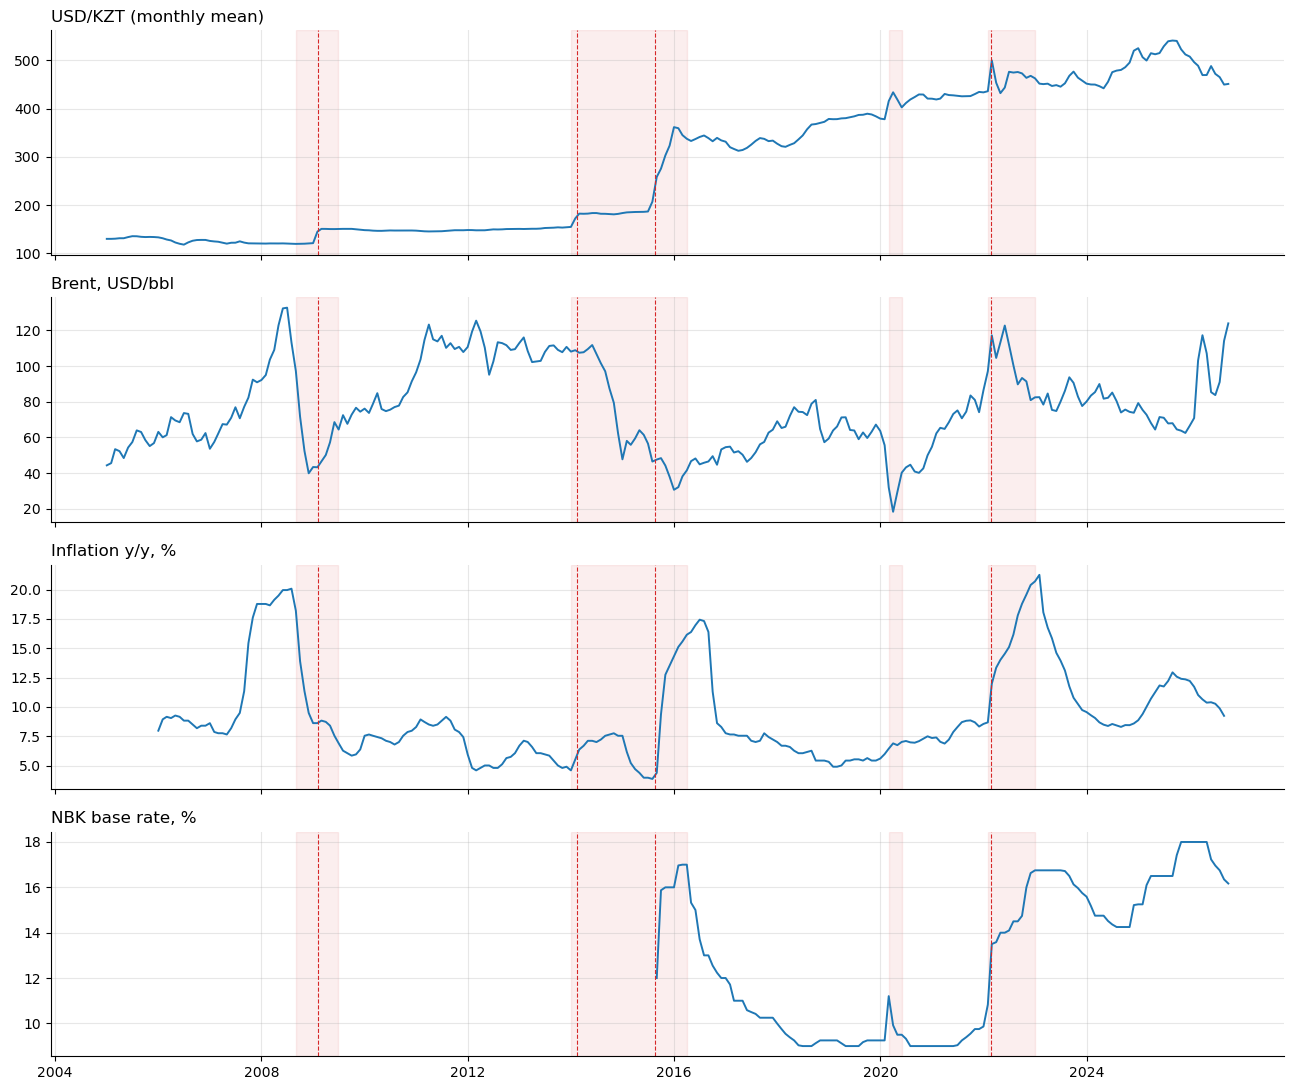

In [43]:
panels = [
    ("usd_kzt", "USD/KZT (monthly mean)"),
    ("brent", "Brent, USD/bbl"),
    ("inflation_yoy", "Inflation y/y, %"),
    ("base_rate", "NBK base rate, %"),
]
fig, axes = plt.subplots(len(panels), 1, figsize=(13, 11), sharex=True)
for ax, (col, title) in zip(axes, panels):
    ax.plot(monthly.index, monthly[col], lw=1.4)
    shade_events(ax)
    ax.set_title(title, loc="left")
plt.tight_layout()
plt.show()

> **Interpretation.** Inflation y/y has three peaks: ~20% in 2007–2008 (this one comes *before* the 2009 devaluation, so it was not caused by FX), 17.4% in 2016 and 21.3% in 2022–2023. The last two follow depreciations (exchange-rate pass-through into prices). The base rate follows inflation with a lag: the NBK raises it after FX and inflation shocks. So the exchange rate, inflation and the base rate move together around crises, which matters for interpreting correlations (part of it is reaction, not cause).

## 7. Structural breaks: devaluations 2009, 2014–2015 and the 2022 shock

### 7.1 Size of each shock

In [44]:
rows = []
for day, name in EVENTS.items():
    d = pd.Timestamp(day)
    before = fx.asof(d - pd.Timedelta(days=1))
    rows.append({
        "event": name,
        "date": d.date(),
        "rate_before": before,
        "after_1_week": fx.asof(d + pd.Timedelta(days=7)),
        "after_3_months": fx.asof(d + pd.Timedelta(days=91)),
        "peak_within_3m": fx[d: d + pd.Timedelta(days=91)].max(),
    })
shocks = pd.DataFrame(rows).set_index("event")
for col in ["after_1_week", "after_3_months", "peak_within_3m"]:
    shocks[col + "_%"] = (shocks[col] / shocks["rate_before"] - 1) * 100
shocks

,date,rate_before,after_1_week,after_3_months,peak_within_3m,after_1_week_%,after_3_months_%,peak_within_3m_%
event,,,,,,,,
Devaluation 2009,2009-02-04,121.870,148.300,150.660,151.400,21.687,23.624,24.231
Devaluation 2014,2014-02-11,155.500,184.500,182.040,184.950,18.650,17.068,18.939
Free float 2015,2015-08-20,188.350,243.990,307.680,312.650,29.541,63.355,65.994
2022 shock,2022-02-24,433.390,490.430,415.120,512.190,13.161,-4.216,18.182


### 7.2 Regime statistics

In [45]:
REGIMES = [
    ("2005-01-01", "2009-02-03", "1. Managed rate"),
    ("2009-02-04", "2014-02-10", "2. Peg after 2009 devaluation"),
    ("2014-02-11", "2015-08-19", "3. Peg after 2014 devaluation"),
    ("2015-08-20", "2022-02-23", "4. Free float"),
    ("2022-02-24", "2022-12-31", "5. 2022 shock"),
    ("2023-01-01", str(fx.index.max().date()), "6. Post-shock float"),
]

rows = []
for start, end, name in REGIMES:
    level = fx[start:end]
    r = np.log(level).diff().dropna()
    rows.append({
        "regime": name,
        "start": start, "end": end,
        "mean_rate": level.mean(),
        "total_change_%": (level.iloc[-1] / level.iloc[0] - 1) * 100,
        "ann_volatility_%": r.std() * np.sqrt(365) * 100,
        "max_daily_move_%": r.abs().max() * 100,
        "share_unchanged_days": (r == 0).mean(),
    })
regimes = pd.DataFrame(rows).set_index("regime")
regimes

,start,end,mean_rate,total_change_%,ann_volatility_%,max_daily_move_%,share_unchanged_days
regime,,,,,,,
1. Managed rate,2005-01-01,2009-02-03,125.345,-6.254,3.495,1.662,0.361
2. Peg after 2009 devaluation,2009-02-04,2014-02-10,149.193,27.126,7.685,16.303,0.350
3. Peg after 2014 devaluation,2014-02-11,2015-08-19,183.616,21.079,10.574,11.839,0.773
4. Free float,2015-08-20,2022-02-23,368.949,130.062,16.732,30.382,0.331
5. 2022 shock,2022-02-24,2022-12-31,465.827,5.816,17.547,6.373,0.320
6. Post-shock float,2023-01-01,2026-11-12,481.158,-3.867,9.117,3.194,0.325


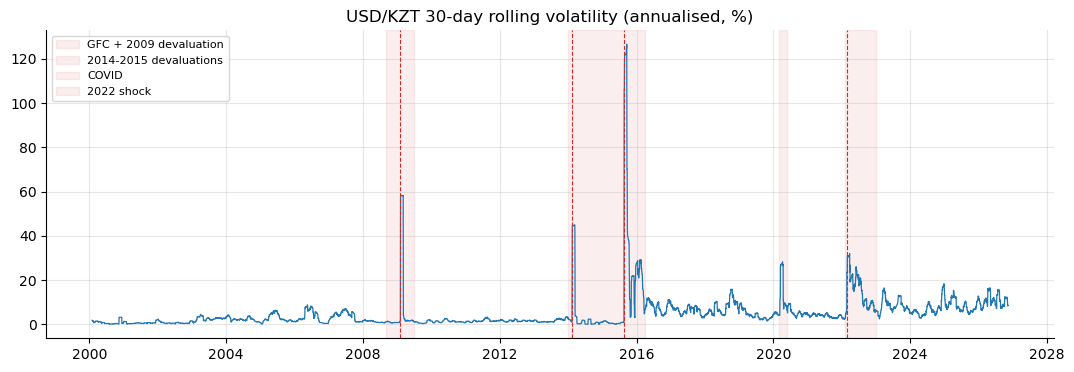

In [46]:
vol_30d = fx_ret.rolling(30).std() * np.sqrt(365)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(vol_30d.index, vol_30d, lw=0.9)
shade_events(ax, labels=True)
ax.set_title("USD/KZT 30-day rolling volatility (annualised, %)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

> **Interpretation.** The regimes differ strongly. Annualised volatility rises from **3.5%** (managed rate) to **7.7% / 10.6%** in the pegs (driven by the devaluation days themselves), and to **16.7%** in the free float and **17.5%** in the 2022 shock, then falls back to **9.1%** after 2023. In the 2014–2015 peg 77% of days had no change at all. The shock table shows **two kinds of shocks**: in 2009, 2014 and 2015 the level shifted **permanently** (+18% to +63% after 3 months), while in 2022 the rate jumped 13–18% and then **fully reversed** (−4% after 3 months). A random walk handles a permanent shift well (the naive forecast adapts after one step) but cannot anticipate either kind of shock.

### 7.3 Formal check: Chow test

Model: `log(USD/KZT)_t = a + b·t + ε` (log-linear trend). The Chow F-statistic compares one trend for the
whole sample with two separate trends before and after a candidate date. We

1. scan every month (trimming 10% at the edges) to see **where the data itself puts the break**;
2. test the known event dates.

Residuals are autocorrelated, so the p-values are too optimistic; the F-statistic profile is
the main result.

In [47]:
y = np.log(monthly["usd_kzt"]).values
X = np.column_stack([np.ones(len(y)), np.arange(len(y))])
K = X.shape[1]


def rss(yv, Xv):
    beta, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
    resid = yv - Xv @ beta
    return resid @ resid


def chow_f(i):
    r_full, r1, r2 = rss(y, X), rss(y[:i], X[:i]), rss(y[i:], X[i:])
    return ((r_full - r1 - r2) / K) / ((r1 + r2) / (len(y) - 2 * K))


trim = int(0.1 * len(y))
chow_profile = pd.Series({monthly.index[i]: chow_f(i) for i in range(trim, len(y) - trim)})
print("Highest F-statistic at:", chow_profile.idxmax().strftime("%Y-%m"), f"(F = {chow_profile.max():.1f})")

Highest F-statistic at: 2015-09 (F = 672.6)


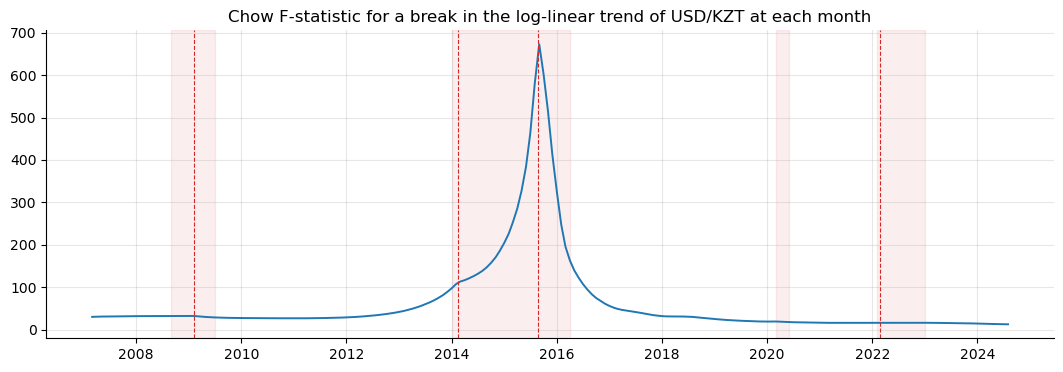

In [48]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(chow_profile.index, chow_profile, lw=1.4)
shade_events(ax)
ax.set_title("Chow F-statistic for a break in the log-linear trend of USD/KZT at each month")
plt.show()

In [49]:
rows = []
for day, name in EVENTS.items():
    i = monthly.index.get_indexer([pd.Timestamp(day).to_period("M").to_timestamp()])[0]
    F = chow_f(i)
    rows.append({"event": name, "break_month": monthly.index[i].strftime("%Y-%m"),
                 "F": F, "p_value": stats.f.sf(F, K, len(y) - 2 * K)})
pd.DataFrame(rows).set_index("event")

,break_month,F,p_value
event,,,
Devaluation 2009,2009-02,32.282,0.000
Devaluation 2014,2014-02,107.570,0.000
Free float 2015,2015-08,580.359,0.000
2022 shock,2022-02,16.104,0.000


> **Interpretation.** The data puts the break in the same place as history. The F-statistic peaks at **2015-09 (F ≈ 673)**, the free float. All four known dates give significant F-statistics: 2015-08 (580) > 2014-02 (108) > 2009-02 (32) > 2022-02 (16). The 2015 float is by far the dominant break. A model fitted on 2005–2015 data would learn the dynamics of a peg, which no longer exists. This is an argument for training on (or at least weighting) the **post-2015 period**.

## 8. Time series analysis

### 8.1 Resampling day → month

Compare the daily series with its two monthly versions (mean and month-end) on the most volatile
period, 2014–2016.

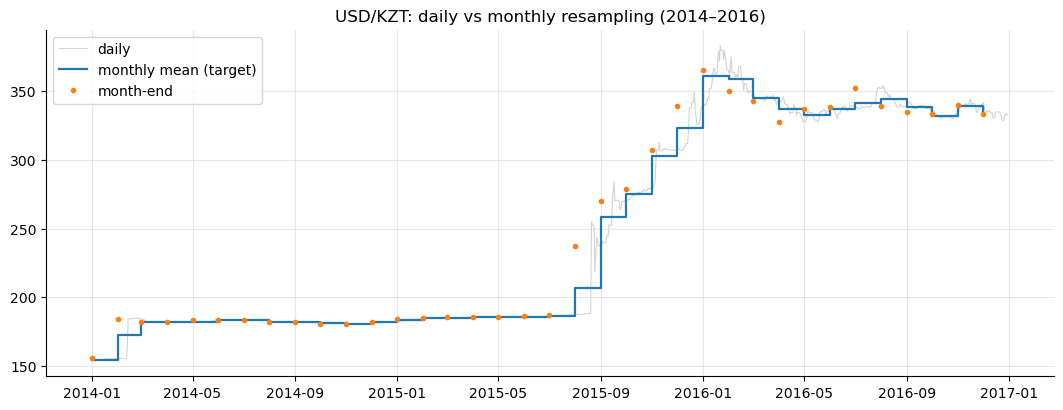

In [50]:
window = slice("2014-01-01", "2016-12-31")
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(fx[window].index, fx[window], lw=0.8, color="lightgrey", label="daily")
ax.step(monthly.loc[window].index, monthly.loc[window, "usd_kzt"], where="post", lw=1.6, label="monthly mean (target)")
ax.plot(monthly.loc[window].index, monthly.loc[window, "usd_kzt_eom"], "o", ms=3, label="month-end")
ax.set_title("USD/KZT: daily vs monthly resampling (2014–2016)")
ax.legend()
plt.show()

In [51]:
diff_mean_eom = (monthly["usd_kzt_eom"] / monthly["usd_kzt"] - 1) * 100
print("Month-end vs monthly mean, %:", diff_mean_eom.describe()[["mean", "std", "min", "max"]].round(2).to_dict())

Month-end vs monthly mean, %: {'mean': 0.22, 'std': 1.68, 'min': -8.31, 'max': 14.82}


> **Interpretation.** The monthly mean smooths the daily path, while the month-end value is noisier: it differs from the monthly mean by 1.7% on average (std), and by up to +14.8% (August 2015) and −8.3%. The **monthly mean is chosen as the target**: it is less sensitive to single-day spikes and has the same definition as the official annual average. The month-end rate is kept as an alternative target.

### 8.2 Rolling means and rolling volatility

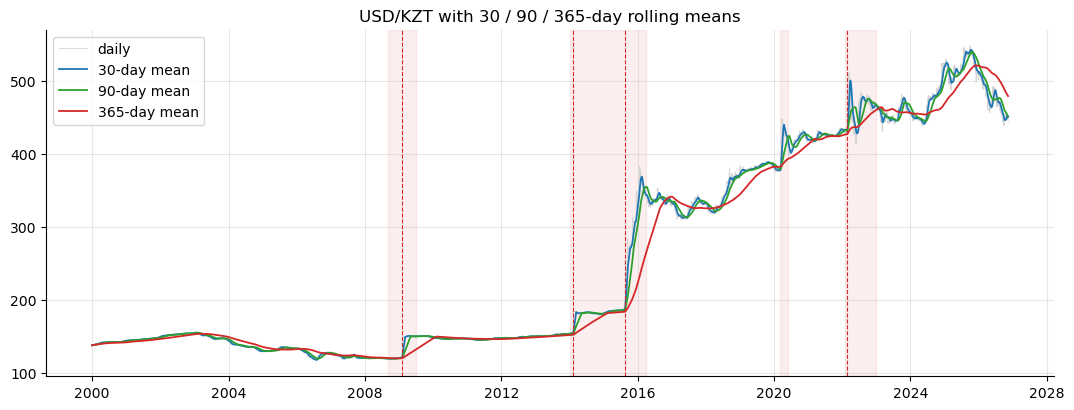

In [52]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(fx.index, fx, lw=0.6, color="lightgrey", label="daily")
for window_days, color in [(30, "tab:blue"), (90, "tab:green"), (365, "tab:red")]:
    ax.plot(fx.index, fx.rolling(f"{window_days}D").mean(), lw=1.3, color=color, label=f"{window_days}-day mean")
shade_events(ax)
ax.set_title("USD/KZT with 30 / 90 / 365-day rolling means")
ax.legend()
plt.show()

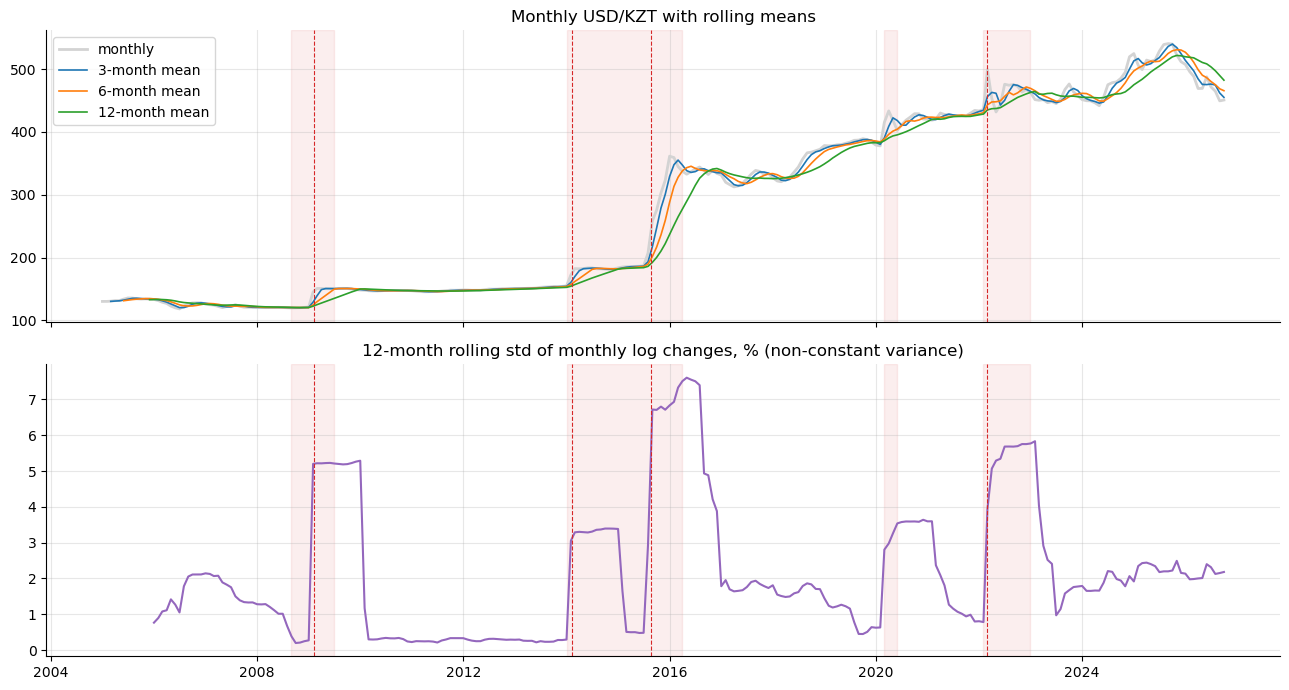

In [53]:
s = monthly["usd_kzt"]
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(s.index, s, color="lightgrey", lw=2, label="monthly")
for w in [3, 6, 12]:
    axes[0].plot(s.index, s.rolling(w).mean(), lw=1.2, label=f"{w}-month mean")
axes[0].set_title("Monthly USD/KZT with rolling means")
axes[0].legend()
axes[1].plot(s.index, monthly["usd_kzt_log_ret"].rolling(12).std(), color="tab:purple")
axes[1].set_title("12-month rolling std of monthly log changes, % (non-constant variance)")
for ax in axes:
    shade_events(ax)
plt.tight_layout()
plt.show()

> **Interpretation.** Rolling means lag behind every jump: the 365-day mean needs about a year to catch up with a step change, so smoothing-based forecasts adapt slowly after breaks. The 12-month rolling std of monthly changes is far from constant. It spikes around 2009, 2015–2016 and 2022 (volatility clustering, heteroscedasticity). This is why errors should be compared across crisis and calm periods, and why we model log changes rather than levels.

### 8.3 STL decomposition

STL splits a series into **trend + seasonal + remainder**. We decompose `log(USD/KZT)` (log makes
the components multiplicative) with a 12-month period and the robust option, so the shocks go
to the remainder instead of distorting the seasonal component.

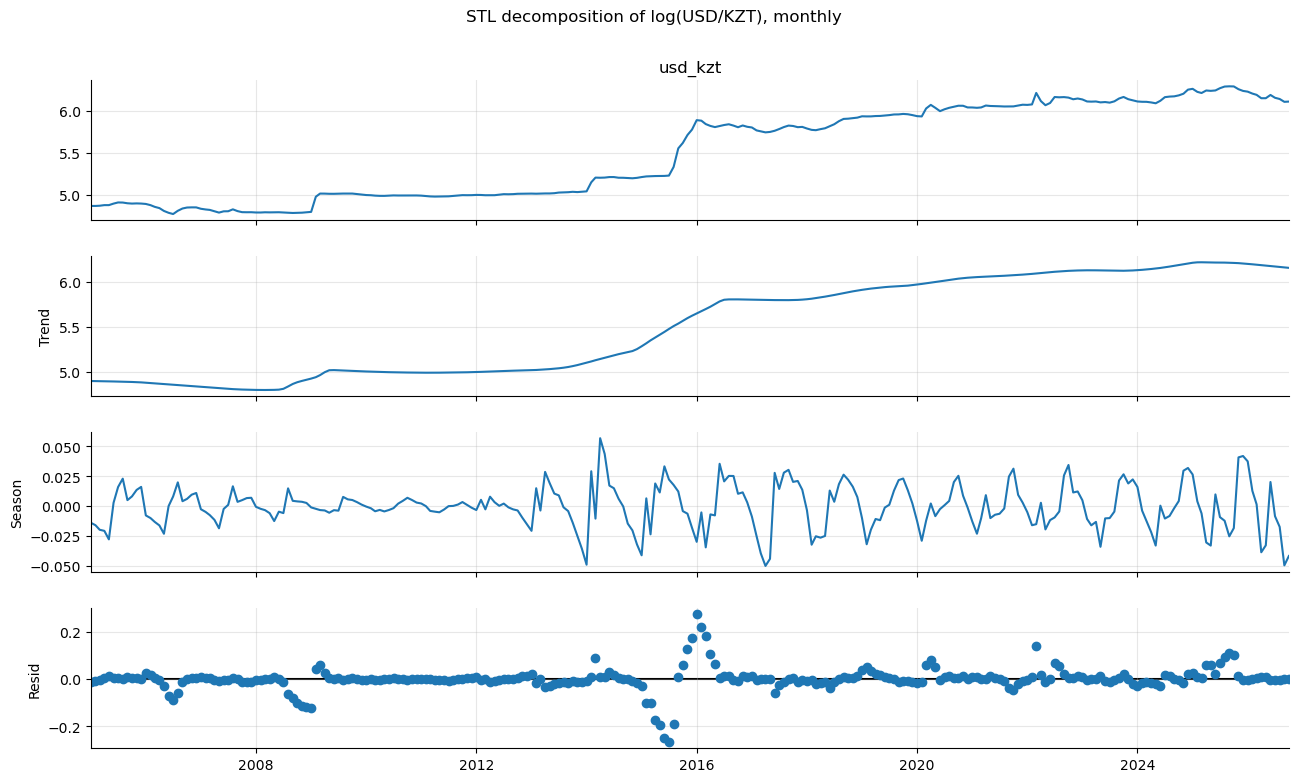

In [54]:
stl_fx = STL(np.log(monthly["usd_kzt"]), period=12, robust=True).fit()
fig = stl_fx.plot()
fig.set_size_inches(13, 8)
fig.suptitle("STL decomposition of log(USD/KZT), monthly", y=1.01)
plt.show()

In [55]:
def stl_strength(res):
    """Hyndman & Athanasopoulos: strength of trend and seasonality in [0, 1]."""
    r, t, s = res.resid, res.trend, res.seasonal
    return {
        "trend_strength": max(0, 1 - r.var() / (t + r).var()),
        "seasonal_strength": max(0, 1 - r.var() / (s + r).var()),
    }


stl_infl = STL(monthly["inflation_mom"].dropna(), period=12, robust=True).fit()
stl_brent = STL(np.log(monthly["brent"]), period=12, robust=True).fit()
pd.DataFrame({
    "log USD/KZT": stl_strength(stl_fx),
    "log Brent": stl_strength(stl_brent),
    "inflation m/m": stl_strength(stl_infl),
}).T

,trend_strength,seasonal_strength
log USD/KZT,0.991,0.000
log Brent,0.749,0.016
inflation m/m,0.129,0.123


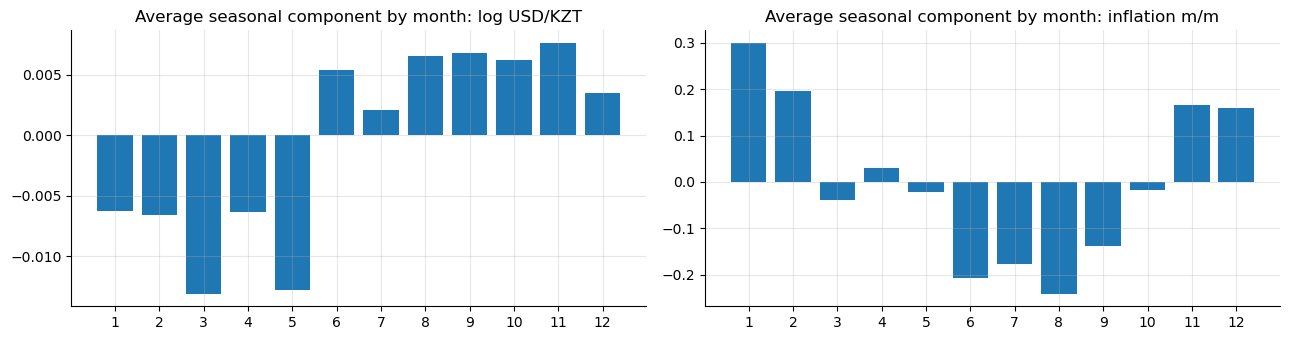

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, res, title in [(axes[0], stl_fx, "log USD/KZT"), (axes[1], stl_infl, "inflation m/m")]:
    seas = res.seasonal.groupby(res.seasonal.index.month).mean()
    ax.bar(seas.index, seas.values)
    ax.set_xticks(range(1, 13))
    ax.set_title(f"Average seasonal component by month: {title}")
plt.tight_layout()
plt.show()

In [57]:
# Where is the remainder largest? -> the months the trend + seasonality cannot explain
stl_fx.resid.abs().nlargest(8).to_frame("|remainder| of log USD/KZT")

,|remainder| of log USD/KZT
date,
2016-01-01,0.274
2015-07-01,0.266
2015-06-01,0.248
2016-02-01,0.219
2015-05-01,0.196
2015-08-01,0.191
2016-03-01,0.183
2015-12-01,0.175


> **Interpretation.** Trend strength is **0.99** and seasonal strength **0.00** for log USD/KZT: the level is almost entirely trend plus shocks, with no seasonal cycle a seasonal model could exploit. The largest remainders all fall in **2015-05 → 2016-03**: even the robust trend cannot follow the free-float jump. Inflation m/m has weak but real seasonality (0.12), and log Brent is mostly trend (0.75).

### 8.4 Stationarity: ADF and KPSS

Two tests with opposite null hypotheses are used together:

* **ADF**: H0 = unit root (non-stationary). p < 0.05 → stationary.
* **KPSS**: H0 = stationary. p < 0.05 → non-stationary.

(KPSS p-values are interpolated from a table, so they are capped at 0.01 and 0.10.)

In [58]:
def stationarity_test(s):
    s = s.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    if adf_p < 0.05 and kpss_p > 0.05:
        verdict = "stationary"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        verdict = "NON-stationary"
    else:
        verdict = "inconclusive"
    return {"n": len(s), "ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kpss_stat, "KPSS p": kpss_p,
            "verdict": verdict}


log_fx = np.log(monthly["usd_kzt"])
log_brent = np.log(monthly["brent"])
series_to_test = {
    "log USD/KZT": log_fx,
    "Δ log USD/KZT": log_fx.diff(),
    "Δ log USD/KZT (float, 2015-09+)": log_fx.diff()["2015-09-01":],
    "log Brent": log_brent,
    "Δ log Brent": log_brent.diff(),
    "inflation y/y": monthly["inflation_yoy"],
    "Δ inflation y/y": monthly["inflation_yoy"].diff(),
    "inflation m/m": monthly["inflation_mom"],
    "base rate": monthly["base_rate"],
    "Δ base rate": monthly["base_rate"].diff(),
}
adf_table = pd.DataFrame({name: stationarity_test(s) for name, s in series_to_test.items()}).T
adf_table

,n,ADF stat,ADF p,KPSS stat,KPSS p,verdict
log USD/KZT,262,-0.685,0.851,2.372,0.010,NON-stationary
Δ log USD/KZT,261,-11.278,0.000,0.126,0.100,stationary
"Δ log USD/KZT (float, 2015-09+)",134,-7.951,0.000,0.405,0.075,stationary
log Brent,262,-3.018,0.033,0.159,0.100,stationary
Δ log Brent,261,-11.422,0.000,0.053,0.100,stationary
inflation y/y,249,-2.624,0.088,0.186,0.100,inconclusive
Δ inflation y/y,248,-5.255,0.000,0.027,0.100,stationary
inflation m/m,260,-6.721,0.000,0.142,0.100,stationary
base rate,134,-1.334,0.613,0.950,0.010,NON-stationary
Δ base rate,133,-11.945,0.000,0.152,0.100,stationary


> **Interpretation.** **log USD/KZT is non-stationary** (ADF p = 0.85, KPSS rejects stationarity). Its first difference is **stationary** both in the full sample and in the float period, so the series is **I(1) → ARIMA with d = 1**. This is also why the naive forecast (random walk) is a strong baseline. The base rate is non-stationary too (use its change). Inflation y/y is very persistent (inconclusive; its difference is stationary), while inflation m/m and Brent returns are stationary. Log Brent is borderline stationary at 5% (ADF p = 0.033), consistent with oil prices mean-reverting over 2005–2026.

### 8.5 ACF and PACF

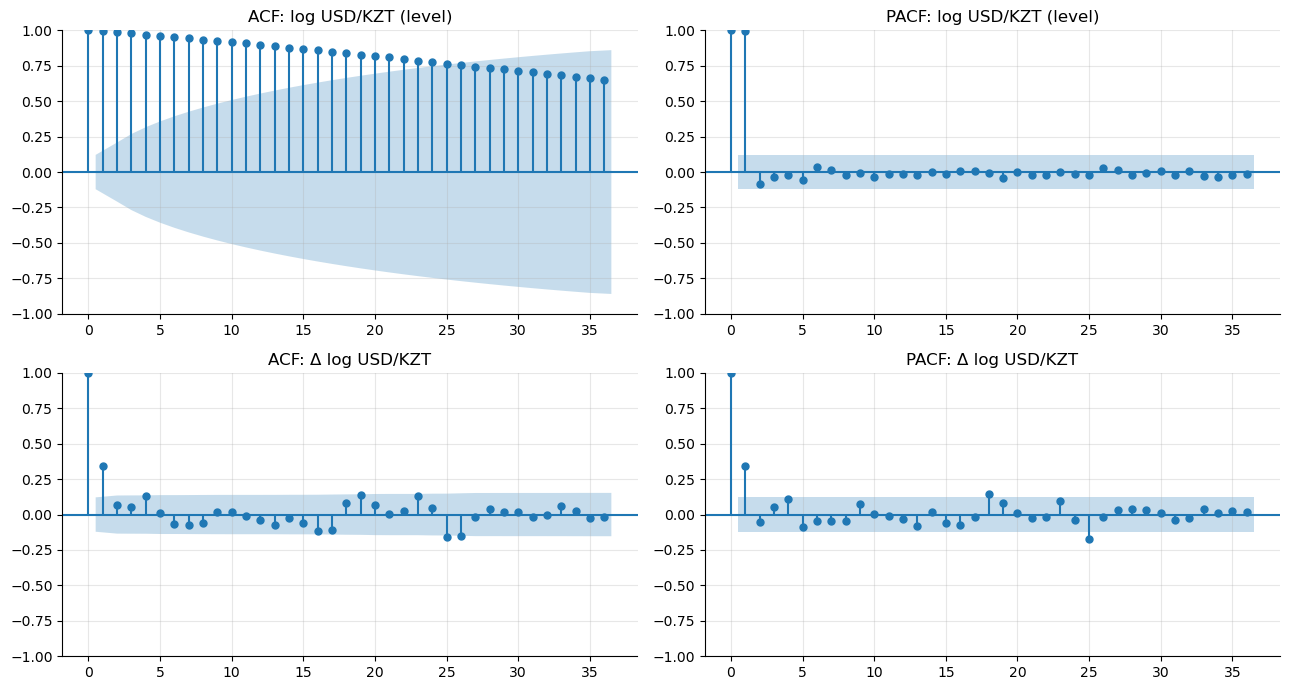

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(log_fx, lags=36, ax=axes[0, 0], title="ACF: log USD/KZT (level)")
plot_pacf(log_fx, lags=36, ax=axes[0, 1], title="PACF: log USD/KZT (level)", method="ywm")
plot_acf(log_fx.diff().dropna(), lags=36, ax=axes[1, 0], title="ACF: Δ log USD/KZT")
plot_pacf(log_fx.diff().dropna(), lags=36, ax=axes[1, 1], title="PACF: Δ log USD/KZT", method="ywm")
plt.tight_layout()
plt.show()

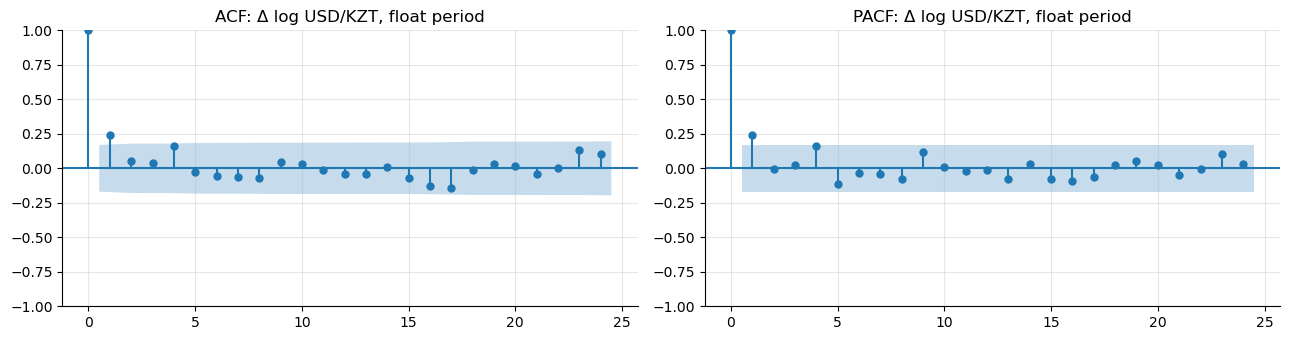

In [60]:
# Same for the float period only: the model will be evaluated on recent years
d_float = log_fx.diff()["2015-09-01":].dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(d_float, lags=24, ax=axes[0], title="ACF: Δ log USD/KZT, float period")
plot_pacf(d_float, lags=24, ax=axes[1], title="PACF: Δ log USD/KZT, float period", method="ywm")
plt.tight_layout()
plt.show()

In [61]:
# Numeric view of the first lags with the 95% band (±1.96/√n)
from statsmodels.tsa.stattools import acf, pacf

band = 1.96 / np.sqrt(len(d_float))
pd.DataFrame({
    "ACF Δlog (float)": acf(d_float, nlags=12)[1:],
    "PACF Δlog (float)": pacf(d_float, nlags=12, method="ywm")[1:],
}, index=pd.RangeIndex(1, 13, name="lag")).style.format("{:.3f}").map(
    lambda v: "font-weight: bold; color: #c0392b" if abs(v) > band else ""
)

,ACF Δlog (float),PACF Δlog (float)
lag,,
1,0.240,0.240
2,0.052,-0.006
3,0.036,0.026
4,0.165,0.160
5,-0.027,-0.113
6,-0.057,-0.034
7,-0.063,-0.044
8,-0.070,-0.078
9,0.048,0.119


> **Interpretation.** Level ACF decays slowly and almost linearly, the classic sign of a unit root. For Δlog USD/KZT (float period, 95% band ±0.17) only **lag 1 is significant (ACF = PACF = 0.24)**. Lag 4 is borderline (0.165), and there are no spikes at 12/24. This means positive momentum: a depreciation month tends to be followed by further depreciation. It suggests **ARIMA(1,1,0)** (or (0,1,1)) as the starting point, and no seasonal ARIMA term.

## 9. Seasonality of USD/KZT changes

Is there a calendar pattern in monthly changes? This decides whether a *seasonal naive* baseline
can be competitive. Kruskal–Wallis tests whether the 12 calendar months share one distribution.

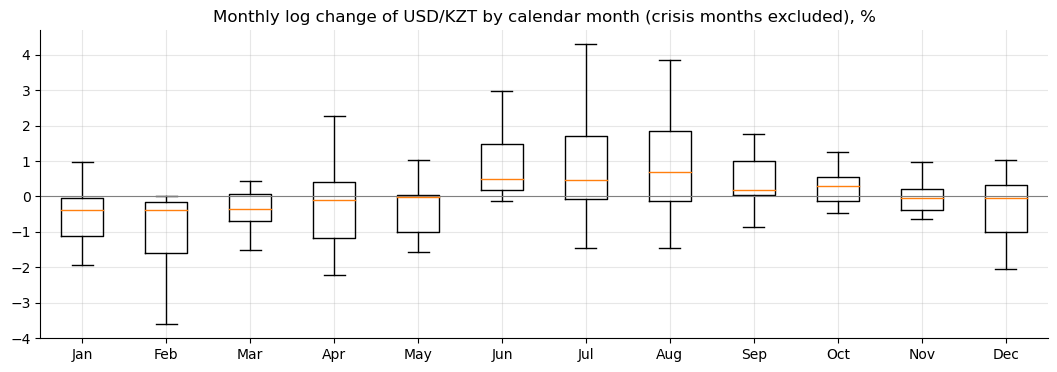

Kruskal–Wallis: H = 44.21, p = 0.000


In [62]:
ret = monthly["usd_kzt_log_ret"].dropna()
calm = ret[monthly.loc[ret.index, "crisis"] == 0]

fig, ax = plt.subplots(figsize=(13, 4))
ax.boxplot([calm[calm.index.month == m] for m in range(1, 13)], showfliers=False)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Monthly log change of USD/KZT by calendar month (crisis months excluded), %")
plt.show()

h_stat, p_value = stats.kruskal(*[calm[calm.index.month == m] for m in range(1, 13)])
print(f"Kruskal–Wallis: H = {h_stat:.2f}, p = {p_value:.3f}")

In [63]:
# Is the pattern stable? Median change by calendar month and the test in each regime
by_regime = {}
for name, part in [("peg (2005–2015-07)", calm[:"2015-07-31"]), ("float (2015-08+)", calm["2015-08-01":])]:
    groups = [part[part.index.month == m] for m in range(1, 13)]
    by_regime[name] = [g.median() for g in groups] + [stats.kruskal(*groups).pvalue]
pd.DataFrame(by_regime, index=[f"median m{m}" for m in range(1, 13)] + ["Kruskal p-value"]).T

,median m1,median m2,median m3,median m4,median m5,median m6,median m7,median m8,median m9,median m10,median m11,median m12,Kruskal p-value
peg (2005–2015-07),-0.319,-0.181,-0.386,-0.155,-0.000,0.273,0.176,0.114,0.116,0.270,-0.067,-0.040,0.065
float (2015-08+),-0.843,-1.600,-0.303,0.203,-0.419,0.868,1.664,1.219,0.283,0.291,-0.044,-1.001,0.006


> **Interpretation.** The Kruskal–Wallis test rejects 'no calendar effect' on the whole calm sample (p < 0.001). The test by regime (table above) shows that the effect is a **free-float phenomenon** (p ≈ 0.006 vs 0.065 in the peg period). In the float, the median monthly change goes from about **−1.6% (February)** and −1.0% (December) to **+1.7% (July)** and +1.2% (August): the tenge tends to strengthen in winter and spring and weaken in summer. This is noticeable against a monthly std of ~3.6%, but it lives in the **changes**, not in the level (STL seasonal strength of the level = 0.00). A *seasonal naive* forecast copies the level of 12 months ago and ignores the trend, so it is still expected to lose to naive. **Month-of-year dummies** in regression / boosting models are worth testing. Possible explanations (timing of exporters' FX sales, tax and dividend periods) are hypotheses and are not tested here.

## 10. Correlations with external factors

Correlations of **levels** of trending series are often spurious (two series that both trend look
correlated). So we look at levels first, then at **changes**, at **lags**, by **regime**, and over **time**.

In [64]:
def plot_corr(corr, title, ax):
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr.index)), corr.index)
    for i in range(corr.shape[0]):
        for j in range(corr.shape[1]):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(title)
    ax.grid(False)
    return im

### 10.1 Levels (2015-09 onwards, when the base rate exists)

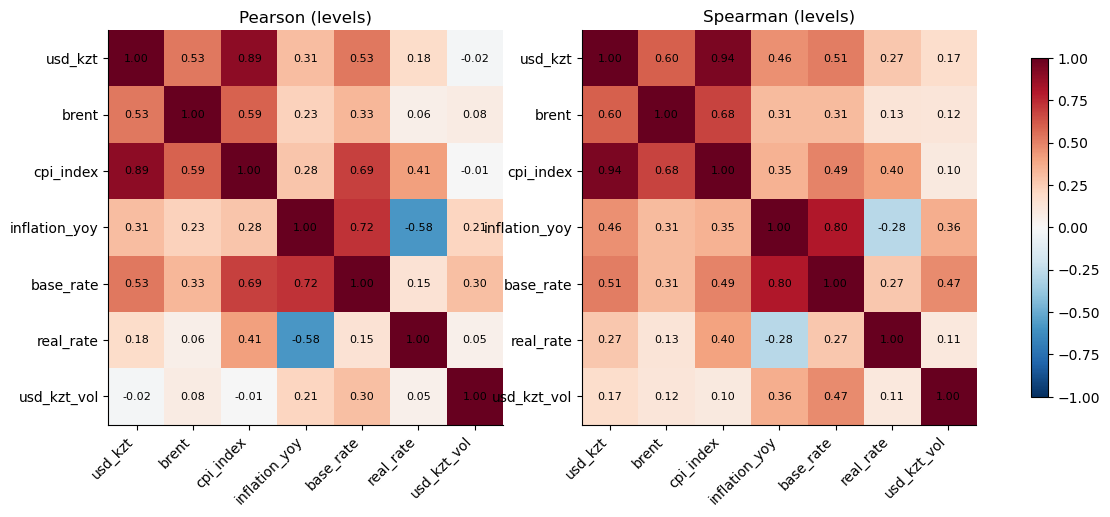

In [65]:
level_cols = ["usd_kzt", "brent", "cpi_index", "inflation_yoy", "base_rate", "real_rate", "usd_kzt_vol"]
levels = monthly.loc["2015-09-01":, level_cols].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_corr(levels.corr(method="pearson"), "Pearson (levels)", axes[0])
im = plot_corr(levels.corr(method="spearman"), "Spearman (levels)", axes[1])
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### 10.2 Changes (monthly)

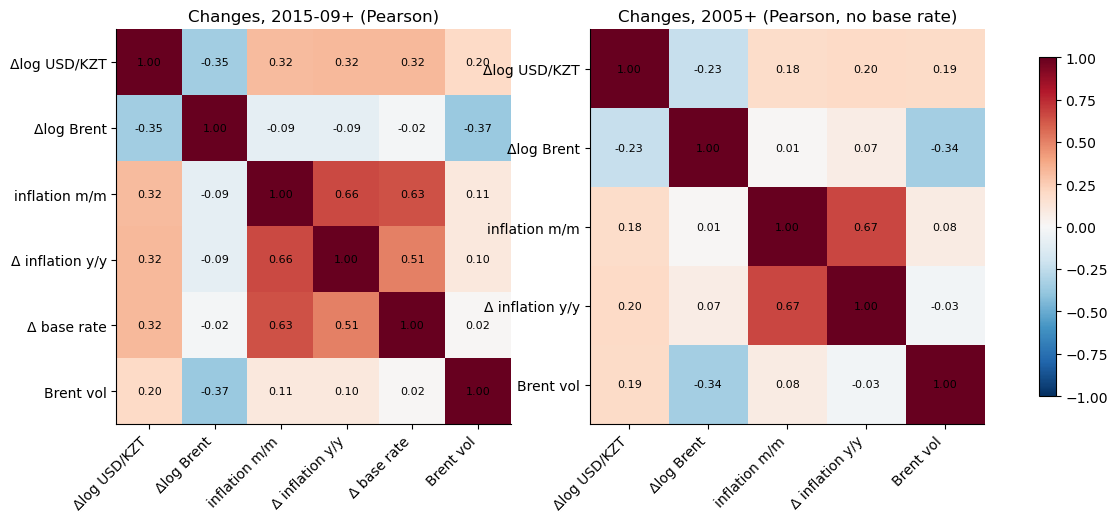

In [66]:
changes = pd.DataFrame({
    "Δlog USD/KZT": monthly["usd_kzt_log_ret"],
    "Δlog Brent": monthly["brent_log_ret"],
    "inflation m/m": monthly["inflation_mom"],
    "Δ inflation y/y": monthly["inflation_yoy"].diff(),
    "Δ base rate": monthly["base_rate"].diff(),
    "Brent vol": monthly["brent_vol"],
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_corr(changes.dropna().corr(), "Changes, 2015-09+ (Pearson)", axes[0])
im = plot_corr(changes.drop(columns="Δ base rate").dropna().corr(), "Changes, 2005+ (Pearson, no base rate)", axes[1])
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

> **Interpretation.** In **levels** (2015-09+), USD/KZT correlates with CPI at 0.89 (Spearman 0.94) and with Brent at 0.53. The CPI correlation is mostly **spurious**: both series trend upwards. In **changes** the picture is more honest. Since 2015-09, Δlog USD/KZT correlates **−0.35 with Δlog Brent** (oil down → tenge weaker), and **+0.32** each with m/m inflation, Δ y/y inflation and Δ base rate. The inflation and base-rate links are mostly reactions: depreciation feeds into prices, and the NBK hikes after a depreciation. Over 2005+ (including the peg) all these correlations are weaker (Brent −0.23).

### 10.3 USD/KZT vs Brent by regime (interactive)

In [67]:
scatter_df = monthly[["usd_kzt_log_ret", "brent_log_ret"]].dropna().copy()
scatter_df["regime"] = np.where(scatter_df.index >= "2015-08-01", "Free float (2015-08+)", "Managed / peg (2005–2015)")
scatter_df["month"] = scatter_df.index.strftime("%Y-%m")

fig = px.scatter(
    scatter_df, x="brent_log_ret", y="usd_kzt_log_ret", color="regime", hover_name="month",
    trendline="ols", opacity=0.7,
    labels={"brent_log_ret": "Brent monthly log change, %", "usd_kzt_log_ret": "USD/KZT monthly log change, %"},
    title="Oil falls → tenge weakens? Monthly changes by exchange-rate regime",
)
fig.update_layout(height=520)
fig.show()

In [68]:
rows = []
for name, part in scatter_df.groupby("regime"):
    r, p = stats.pearsonr(part["brent_log_ret"], part["usd_kzt_log_ret"])
    rho, p_s = stats.spearmanr(part["brent_log_ret"], part["usd_kzt_log_ret"])
    slope = np.polyfit(part["brent_log_ret"], part["usd_kzt_log_ret"], 1)[0]
    rows.append({"regime": name, "months": len(part), "pearson_r": r, "pearson_p": p,
                 "spearman_rho": rho, "spearman_p": p_s, "beta (% FX per 1% Brent)": slope})
pd.DataFrame(rows).set_index("regime")

,months,pearson_r,pearson_p,spearman_rho,spearman_p,beta (% FX per 1% Brent)
regime,,,,,,
Free float (2015-08+),135,-0.307,0.000,-0.270,0.002,-0.090
Managed / peg (2005–2015),126,-0.050,0.581,-0.164,0.067,-0.012


> **Interpretation.** The oil link **depends on the regime**. In the free float r = −0.31 (p < 0.001, Spearman −0.27): a 10% fall in Brent in a month is associated with about **+0.9%** USD/KZT in the same month. Under the peg the monthly correlation is ≈ 0 (r = −0.05, p = 0.58): oil shocks were absorbed by reserves and released through occasional devaluations rather than month-to-month moves.

### 10.4 Rolling 24-month correlation with Brent

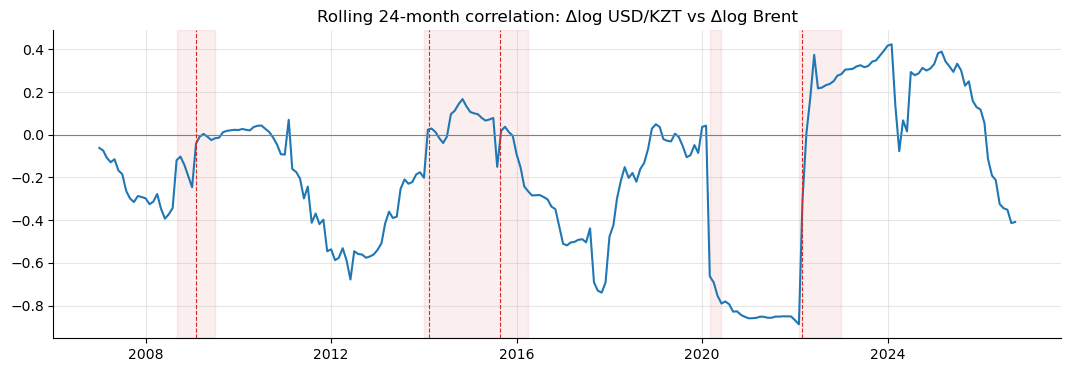

In [69]:
roll_corr = monthly["usd_kzt_log_ret"].rolling(24).corr(monthly["brent_log_ret"])
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(roll_corr.index, roll_corr, lw=1.5)
ax.axhline(0, color="grey", lw=0.8)
shade_events(ax)
ax.set_title("Rolling 24-month correlation: Δlog USD/KZT vs Δlog Brent")
plt.show()

> **Interpretation.** The 24-month correlation is unstable. It was most negative in 2020–2021 (down to **−0.89** for the window ending February 2022), turned **positive in 2023–2025** (up to +0.42), and is negative again in 2026. After 2022 the oil channel was dominated by other factors. The oil correlation is real but **not stable enough** to rely on as the single driver of a forecast.

### 10.5 Lagged correlations: does a factor *lead* the exchange rate?

For forecasting only lagged information is available, so we need `corr(Δlog USD/KZT_t, X_{t−k})`.
Free-float period only.

In [70]:
float_part = monthly["2015-09-01":]
drivers = {
    "Δlog Brent": float_part["brent_log_ret"],
    "inflation m/m": float_part["inflation_mom"],
    "Δ base rate": float_part["base_rate"].diff(),
    "real rate": float_part["real_rate"],
    "Δlog USD/KZT (own lag)": float_part["usd_kzt_log_ret"],
}
target_ret = float_part["usd_kzt_log_ret"]
lag_corr = pd.DataFrame({
    name: [target_ret.corr(x.shift(k)) for k in range(0, 7)] for name, x in drivers.items()
}, index=pd.RangeIndex(0, 7, name="lag (months)"))
band = 1.96 / np.sqrt(target_ret.notna().sum())
print(f"95% significance band: ±{band:.3f}")
lag_corr.style.format("{:.3f}").map(lambda v: "font-weight: bold; color: #c0392b" if abs(v) > band else "")

95% significance band: ±0.169


,Δlog Brent,inflation m/m,Δ base rate,real rate,Δlog USD/KZT (own lag)
lag (months),,,,,
0,-0.285,0.280,0.320,0.105,1.000
1,-0.123,0.064,0.152,0.077,0.286
2,0.122,0.114,-0.016,0.060,0.064
3,0.071,0.149,0.121,0.088,0.047
4,0.029,0.014,0.116,0.096,0.216
5,0.038,-0.112,-0.061,0.044,-0.035
6,-0.072,-0.088,-0.092,0.039,-0.077


Granger causality (float period, stationary series): does the past of a factor improve the prediction of Δlog USD/KZT?

In [71]:
def granger_p(target, cause, maxlag=6):
    data = pd.concat([target, cause], axis=1).dropna()
    with redirect_stdout(io.StringIO()):
        res = grangercausalitytests(data, maxlag=maxlag)
    return {lag: res[lag][0]["ssr_ftest"][1] for lag in range(1, maxlag + 1)}


pd.DataFrame({
    name: granger_p(target_ret, x) for name, x in drivers.items() if "own" not in name
}).rename_axis("lag").style.format("{:.3f}").map(lambda v: "font-weight: bold" if v < 0.05 else "")

,Δlog Brent,inflation m/m,Δ base rate,real rate
lag,,,,
1,0.603,0.842,0.330,0.604
2,0.108,0.297,0.667,0.889
3,0.207,0.000,0.070,0.022
4,0.299,0.000,0.304,0.036
5,0.554,0.000,0.293,0.353
6,0.605,0.000,0.392,0.464


> **Interpretation.** Brent's effect is almost entirely **contemporaneous** (lag 0: −0.29). Lagged oil changes are inside the significance band, and Brent does **not Granger-cause** USD/KZT at any lag (p > 0.1). To use oil in a forecast you would need an oil forecast. The own lag 1 (0.29) is significant, the same momentum as the ACF. **m/m inflation Granger-causes Δlog USD/KZT at lags 3–6 (p < 0.001)**, and the result holds when 2015–2016 is excluded (sample from 2017). This makes lagged inflation the most promising external feature. The real rate is borderline (lags 3–4, p ≈ 0.02–0.04, not robust from 2017). Changes in the base rate have no predictive power. Caveat: Granger tests are in-sample. The real check is out-of-sample forecast accuracy.

### 10.6 Annual view: World Bank indicators vs annual change of USD/KZT

In [72]:
annual = wb.loc[2000:].copy()
annual["usd_kzt_change_%"] = (annual["usd_kzt_annual_avg"] / annual["usd_kzt_annual_avg"].shift(1) - 1) * 100
annual["brent_avg"] = brent.groupby(brent.index.year).mean()
annual_corr = annual.drop(columns="usd_kzt_annual_avg").corr()["usd_kzt_change_%"].drop("usd_kzt_change_%")
annual_corr.sort_values().to_frame("corr with annual USD/KZT change")

,corr with annual USD/KZT change
indicator,
gdp_growth_pct,-0.549
exports_pct_gdp,-0.506
unemployment_pct,-0.343
brent_avg,-0.128
gdp_usd_bn,0.166
inflation_cpi_pct,0.181


> **Interpretation.** On an annual basis, depreciation years coincide with **weak GDP growth (−0.55)** and a **lower export share (−0.51)**, e.g. 2009 and 2015–2016. These are contemporaneous correlations on ~25 points, so they are descriptive only. In the monthly dataset the World Bank indicators enter with a one-year lag to avoid leakage.

## 11. Key findings and modelling plan

### Summary

**Data and merging**
* Five sources at four frequencies (daily calendar, business-day, monthly, irregular decisions, annual) were merged into **one monthly dataframe**: `data/processed/monthly_dataset.csv`, 262 months (2005-01 → 2026-10), 25 columns. Target: `usd_kzt` (monthly mean).
* USD/KZT has rows for all calendar days, but Sunday/Monday are copies of the previous day; the real gaps (55 days, mainly August 2023) were filled by interpolation and flagged.
* World Bank data enters with a one-year lag (no leakage). The base rate exists only from 2015-09.

**Structural breaks**
* Four shocks: 2009 (+22% in a week), 2014 (+19%), **2015 free float (+30% in a week, +63% in 3 months, the dominant break, Chow F peak at 2015-09)**, and 2022 (+13–18%, then fully reversed).
* Volatility regimes differ by a factor of 5 (3.5% → 17.5% annualised). Pre-2015 dynamics (peg) are not representative of the current float.

**Time series properties**
* log USD/KZT is **I(1)**: ADF/KPSS agree, and the difference is stationary → **d = 1**, random walk = strong baseline.
* Δlog USD/KZT has a significant **lag-1 autocorrelation (0.24)** → ARIMA(1,1,0) / (0,1,1) as a starting point.
* **No seasonality in the level** (STL seasonal strength 0.00). There is a calendar pattern in monthly changes in the float regime (median −1.6% in February vs +1.7% in July): worth testing as month dummies, but seasonal naive on the level should still lose to naive.

**Correlations**
* Brent: **−0.31 to −0.35 with monthly changes in the float regime**, ≈ 0 under the peg. Unstable over time (positive in 2023–2025). Almost purely contemporaneous; does not Granger-cause the rate.
* Inflation m/m: the only factor with **predictive power at lags 3–6** (Granger, robust from 2017).
* Level correlations (0.89 with CPI) are mostly spurious trends.

### Modelling plan (next notebook)

| Step | Decision |
|------|----------|
| Target | `usd_kzt` (monthly mean); models on `log`, metrics on the level |
| Sample | main: 2015-09 → 2026-10 (float regime; base rate available); robustness: 2005+ for univariate models |
| Validation | chronological hold-out (last 24 months) **and** `TimeSeriesSplit` / expanding window, horizon 1–3 months, no shuffling |
| Baselines | **naive** (last value) and **seasonal naive** (value 12 months ago) |
| Models | ARIMA(p,1,q) (start (1,1,0)); linear regression on lags (Δlog FX lags 1–3, inflation m/m lags 1–6, Δlog Brent lag 1, real rate, crisis dummies, month dummies); gradient boosting on the same lags; optionally ARIMAX with exogenous lagged inflation |
| Features | only information available at forecast time: lag every exogenous variable by ≥ 1 month (CPI lag), World Bank by 1 year |
| Metrics | MAE, RMSE, MAPE, **MASE** (scaled by the naive forecast), training time |
| Error analysis | split errors into `crisis = 1` vs calm months, and around 2015, 2020 and 2022: we expect every model to fail at the jumps themselves and to differ mainly in how fast it adapts afterwards |

In [73]:
# Final dataframe for modelling
print(monthly.shape)
monthly.loc["2015-08-01":].describe().T[["count", "mean", "std", "min", "max"]]

(262, 25)


,count,mean,std,min,max
usd_kzt,135.000,413.507,68.090,206.989,540.749
usd_kzt_eom,135.000,414.450,67.194,237.660,548.790
usd_kzt_min,135.000,406.519,67.875,187.450,535.130
usd_kzt_max,135.000,421.064,68.285,255.260,549.150
usd_kzt_vol,135.000,2.657,3.276,0.501,34.584
usd_kzt_obs,135.000,30.207,2.428,4.000,31.000
brent,135.000,69.114,20.466,18.378,123.927
brent_eom,135.000,69.344,21.098,14.850,126.690
brent_vol,135.000,11.423,9.212,4.841,92.201
cpi_index,134.000,114.122,34.744,64.687,186.800
